# GPSA Analysis - WT vs S466R (only reps 1 and 2)

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO


## Delta Energy Terms

### Load data

In [4]:
def load_finalenergy (mut, reps):
    dfs = []
    for rep in range(1, reps + 1):
        energyfile = (f'../../data/1bf5/{mut}/rep{rep}/analysis/006_gbsa/FINAL_ENERGY.csv')
        with open(energyfile, 'r') as f:
            lines = f.readlines()

        # Find the index of the line containing "Delta Energy Terms"
        start_idx = None
        for i, line in enumerate(lines):
            if "Delta Energy Terms" in line:
                start_idx = i + 1  # Start from the next line
                break

        if start_idx is None:
            raise ValueError("Section 'Delta Energy Terms' not found in the file")

        # Extract the lines after "Delta Energy Terms"
        data_lines = lines[start_idx:]
        data_string = ''.join(data_lines)
        df = pd.read_csv(StringIO(data_string))
        dfs.append(df)
    return dfs


In [5]:
wt_delta_dfs = load_finalenergy('wt', 3)
S466R_delta_dfs = load_finalenergy('S466R', 2)

In [6]:
len(wt_delta_dfs)

3

In [7]:
len(S466R_delta_dfs)

2

In [8]:
wt_delta_dfs[0].head()

,Frame #,BOND,ANGLE,DIHED,VDWAALS,EEL,1-4 VDW,1-4 EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
0,1000,0.0,0.0,0.0,-133.98,-277.39,0.0,0.0,260.99,-18.82,-411.37,242.17,-169.21
1,1001,0.0,0.0,0.0,-137.18,-297.28,-0.0,-0.0,281.92,-18.93,-434.46,262.98,-171.48
2,1002,-0.0,-0.0,-0.0,-135.61,-299.07,-0.0,0.0,282.32,-20.45,-434.68,261.87,-172.81
3,1003,0.0,0.0,0.0,-134.28,-298.42,0.0,0.0,283.22,-19.71,-432.69,263.52,-169.18
4,1004,-0.0,-0.0,0.0,-131.69,-282.88,-0.0,0.0,266.81,-19.98,-414.57,246.83,-167.74


Columns: 
- BOND: Bond stretching energy
- ANGLE: Angle bending energy
- DIHED: Dihedral (torsional) energy
- VDWAALS: van der Waals energy
- EEL: Electrostatic energy
- 1-4 VDW: 1-4 van der Waals energy
- 1-4 EEL: 1-4 Electrostatic energy
- EGB: Generalized Born energy
- ESURF: Surface (non-polar solvation) energy
- GGAS: Gas-phase energy. (BOND + ANGLE + DIHED + VDWAALS + EEL + 1-4 VDW + 1-4 EEL)
- GSOLV: Solvation energy. (EGB + ESURF)
- TOTAL: Total energy. (GGAS + GSOLV)

### By replicate

Plot delta energy terms by replicate.

In [9]:
wt_delta_dfs[0].describe()

,Frame #,BOND,ANGLE,DIHED,VDWAALS,EEL,1-4 VDW,1-4 EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
count,1002.000000,1002.0,1002.0,1002.0,1002.000000,1002.000000,1002.0,1002.0,1002.000000,1002.000000,1002.000000,1002.000000,1002.000000
mean,1500.500000,0.0,0.0,0.0,-147.208054,-321.256806,0.0,0.0,304.558393,-19.942605,-468.464551,284.615729,-183.848743
std,289.396786,0.0,0.0,0.0,9.438355,25.177154,0.0,0.0,23.818368,0.911887,27.355557,23.564614,9.822645
min,1000.000000,-0.0,0.0,0.0,-176.550000,-398.030000,0.0,-0.0,242.260000,-22.610000,-551.770000,222.510000,-217.090000
25%,1250.250000,0.0,0.0,0.0,-154.020000,-337.855000,0.0,0.0,288.500000,-20.540000,-486.032500,268.350000,-190.877500
50%,1500.500000,0.0,0.0,0.0,-147.720000,-318.480000,0.0,0.0,302.130000,-19.970000,-466.715000,282.260000,-184.310000
75%,1750.750000,0.0,-0.0,0.0,-140.545000,-304.205000,0.0,0.0,320.137500,-19.330000,-450.807500,299.782500,-176.625000
max,2001.000000,-0.0,0.0,0.0,-120.250000,-253.990000,0.0,-0.0,378.590000,-17.110000,-391.460000,358.500000,-156.460000


In [10]:
wt_delta_summary = []

for df in wt_delta_dfs:
    desc = df.describe()
    desc = desc.filter(items = ['mean', 'std'], axis=0)
    desc.loc['sem'] = df.sem()
    desc = desc.drop(['Frame #', 'BOND', 'ANGLE', 'DIHED', '1-4 VDW', '1-4 EEL'], axis=1)
    wt_delta_summary.append(desc)

S466R_delta_summary = []

for df in S466R_delta_dfs:
    desc = df.describe()
    desc = desc.filter(items = ['mean', 'std'], axis=0)
    desc.loc['sem'] = df.sem()
    desc = desc.drop(['Frame #', 'BOND', 'ANGLE', 'DIHED', '1-4 VDW', '1-4 EEL'], axis=1)
    S466R_delta_summary.append(desc)

In [11]:
wt_delta_summary[0]

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-147.208054,-321.256806,304.558393,-19.942605,-468.464551,284.615729,-183.848743
std,9.438355,25.177154,23.818368,0.911887,27.355557,23.564614,9.822645
sem,0.298169,0.795377,0.752451,0.028808,0.864195,0.744434,0.310309


In [12]:
S466R_delta_summary[0]

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-108.446008,-458.894092,435.424202,-15.979142,-567.339900,419.445010,-147.894950
std,8.386016,21.134896,19.891451,1.124474,22.952805,19.668129,8.966867
sem,0.264924,0.667677,0.628395,0.035523,0.725107,0.621340,0.283274


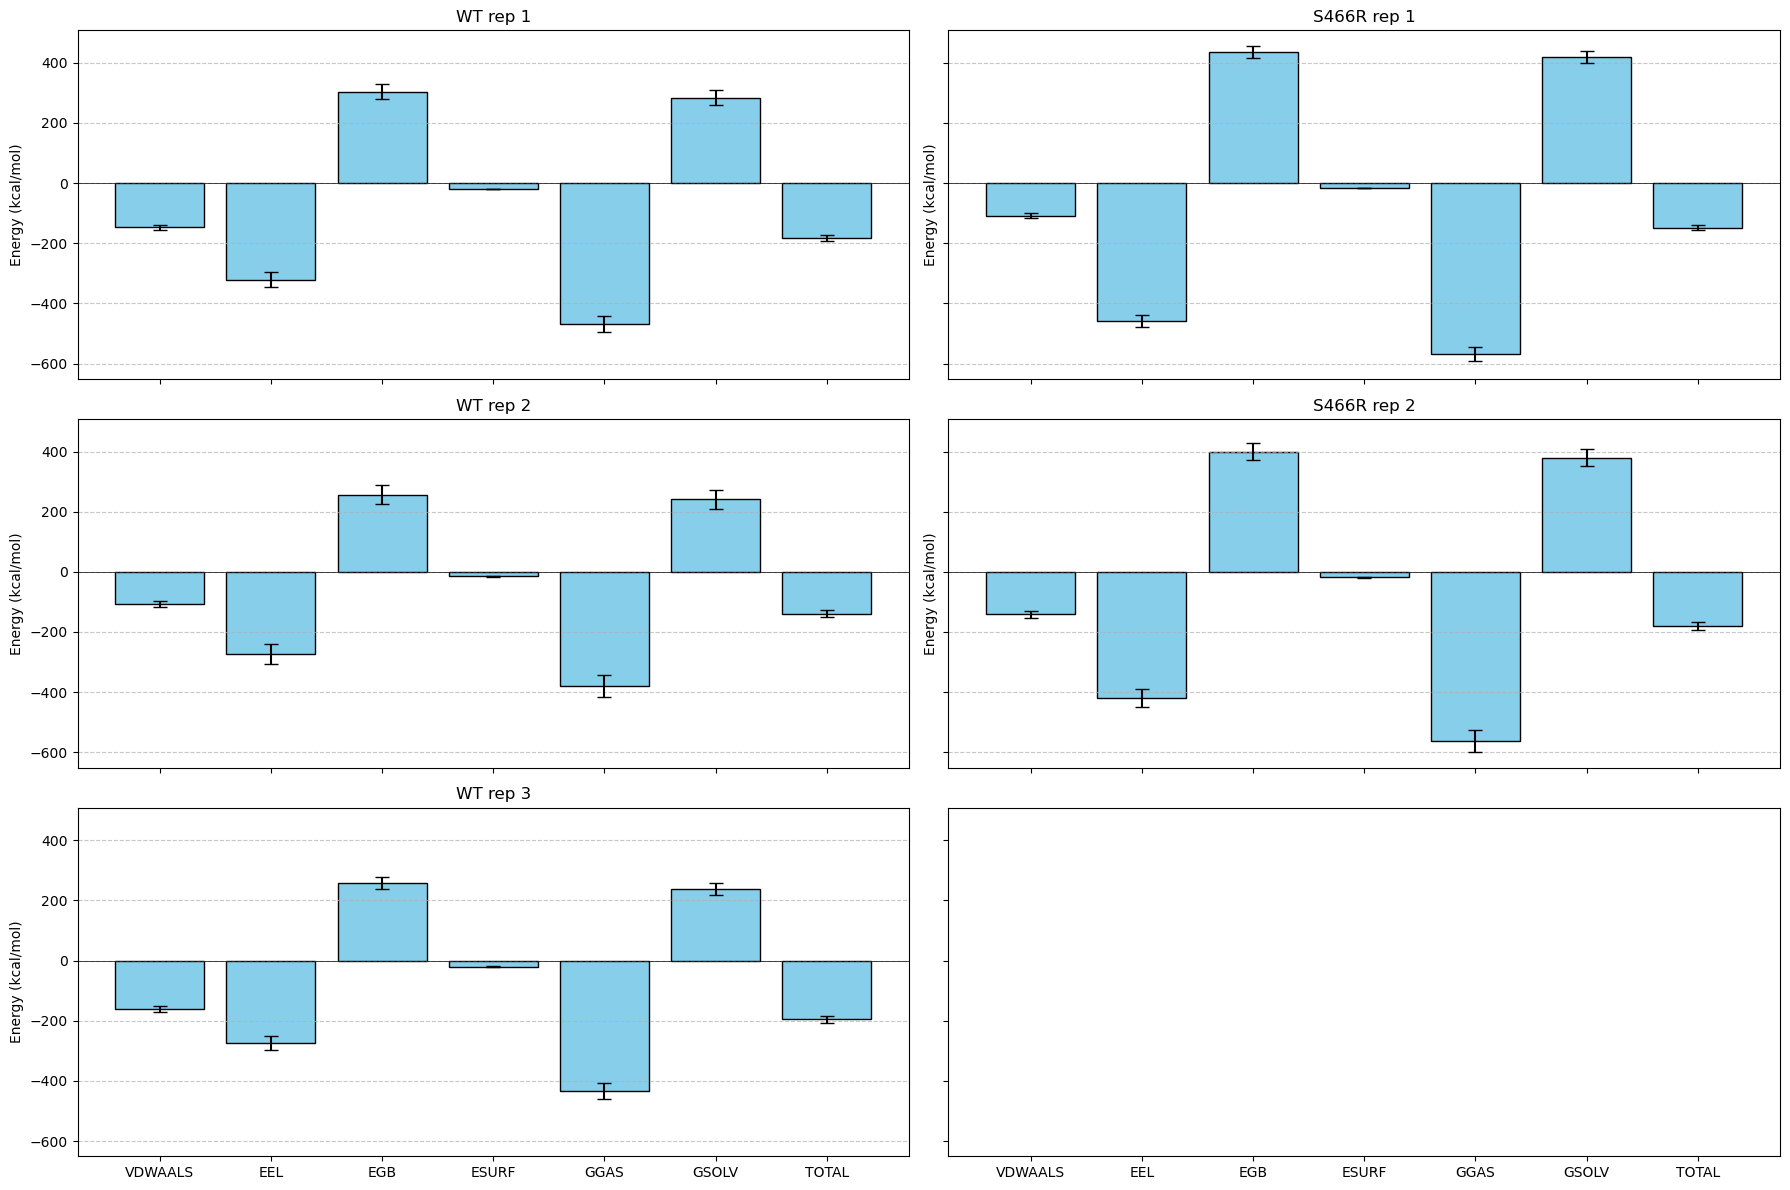

In [13]:

# Find global min and max
all_data = [
    wt_delta_summary[0].transpose().values,
    wt_delta_summary[1].transpose().values,
    wt_delta_summary[2].transpose().values,
    S466R_delta_summary[0].transpose().values,
    S466R_delta_summary[1].transpose().values
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(3, 2, figsize=(18, 12), sharey=True, sharex=True)
ax1, ax2, ax3, ax4, ax5, ax6 = axes.flatten()

plots = [
    (wt_delta_summary[0].transpose(), ax1, 'WT rep 1'),
    (S466R_delta_summary[0].transpose(), ax2, 'S466R rep 1'),
    (wt_delta_summary[1].transpose(), ax3, 'WT rep 2'),
    (S466R_delta_summary[1].transpose(), ax4, 'S466R rep 2'),
    (wt_delta_summary[2].transpose(), ax5, 'WT rep 3')
]

for df, ax, title in plots:
    ax.bar(df.index, df['mean'], yerr=df['std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)


plt.tight_layout()
plt.show()

#### Interpretation


### By mutation (combining replicates)

In [14]:
def combine_delta(dfs):
    combined_means = []
    combined_stds = []

    # Combine for each energy term
    for col in dfs[0].columns:
        means = [df.loc['mean', col] for df in dfs]
        stds = [df.loc['std', col] for df in dfs]
        
        # Simple mean 
        combined_mean = np.mean(means)
        
        # Pooled variance and combined std
        variances = [s**2 for s in stds]
        pooled_variance = np.mean(variances)  # Since n_frames is the same, (n-1) terms cancel out
        combined_std = np.sqrt(pooled_variance)
        
        combined_means.append(combined_mean)
        combined_stds.append(combined_std)

    combined_df = pd.DataFrame({
        col: [combined_means[i], combined_stds[i]] for i, col in enumerate(wt_delta_summary[0].columns)
    }, index=['mean', 'std'])
    return combined_df


In [15]:
wt_combined_df = combine_delta(wt_delta_summary)
S466R_combined_df = combine_delta(S466R_delta_summary)

In [16]:
wt_combined_df 

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-137.768796,-289.567532,273.126104,-18.365023,-427.336244,254.760951,-172.575176
std,9.984252,27.278466,25.747698,1.298792,30.623010,25.194886,11.030096


In [17]:
S466R_combined_df

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-125.092111,-439.435080,417.139701,-17.393458,-564.527071,399.746203,-164.780958
std,9.936660,25.801514,24.259482,1.192004,30.419044,23.791751,11.347652


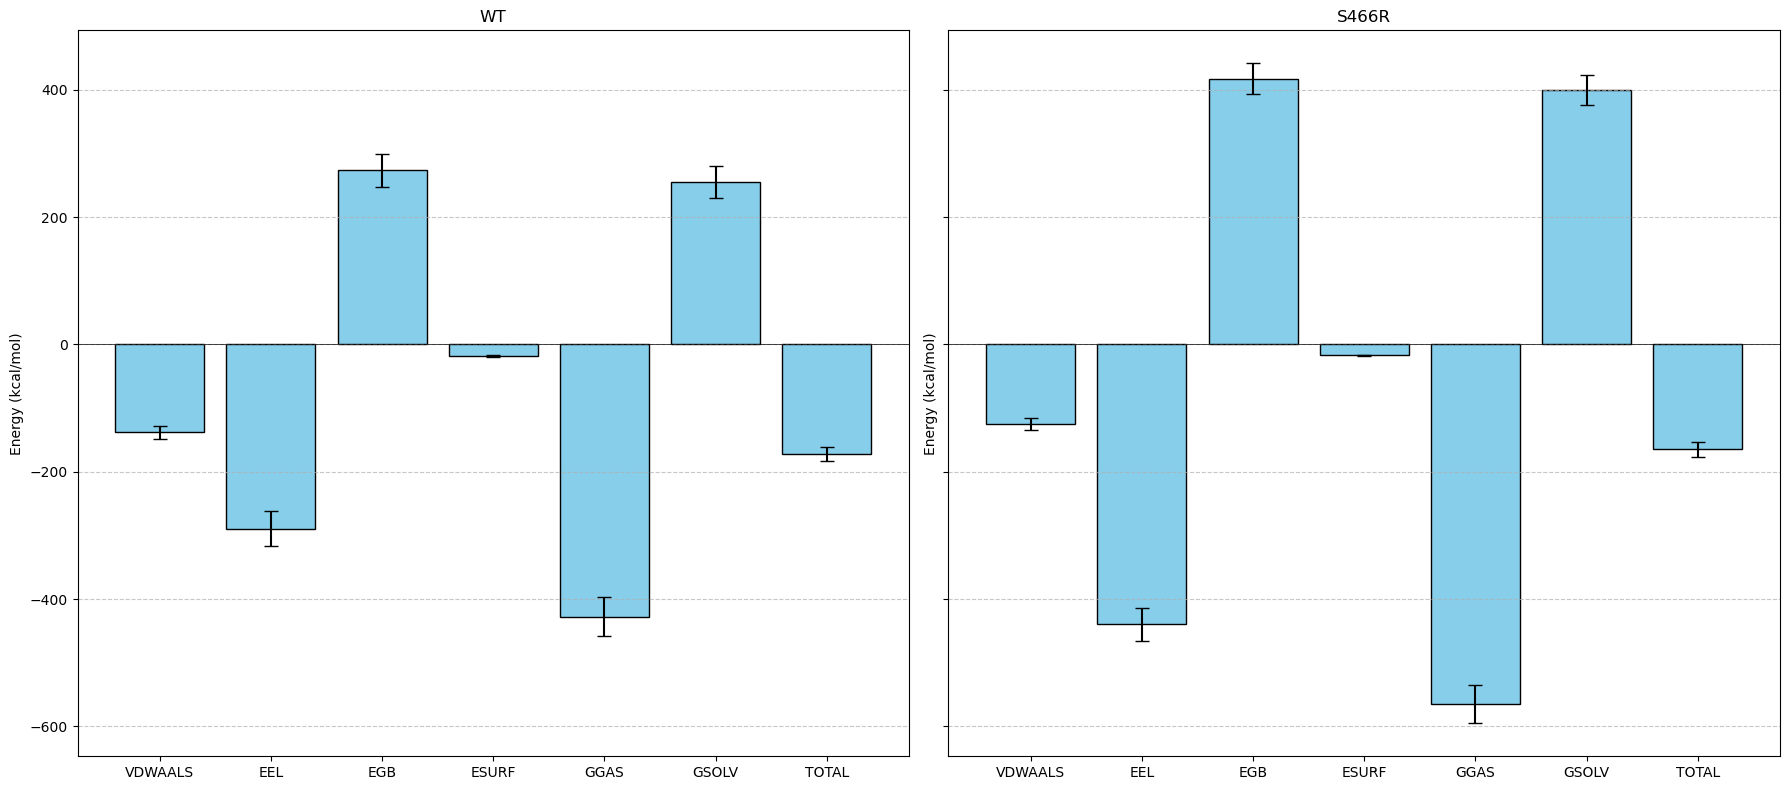

In [18]:

# Find global min and max
all_data = [
    wt_combined_df.transpose().values,
    S466R_combined_df.transpose().values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharey=True, sharex=True)
ax1, ax2 = axes.flatten()

plots = [
    (wt_combined_df.transpose(), ax1, 'WT'),
    (S466R_combined_df.transpose(), ax2, 'S466R'),
]

for df, ax, title in plots:
    ax.bar(df.index, df['mean'], yerr=df['std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)


plt.tight_layout()
plt.show()

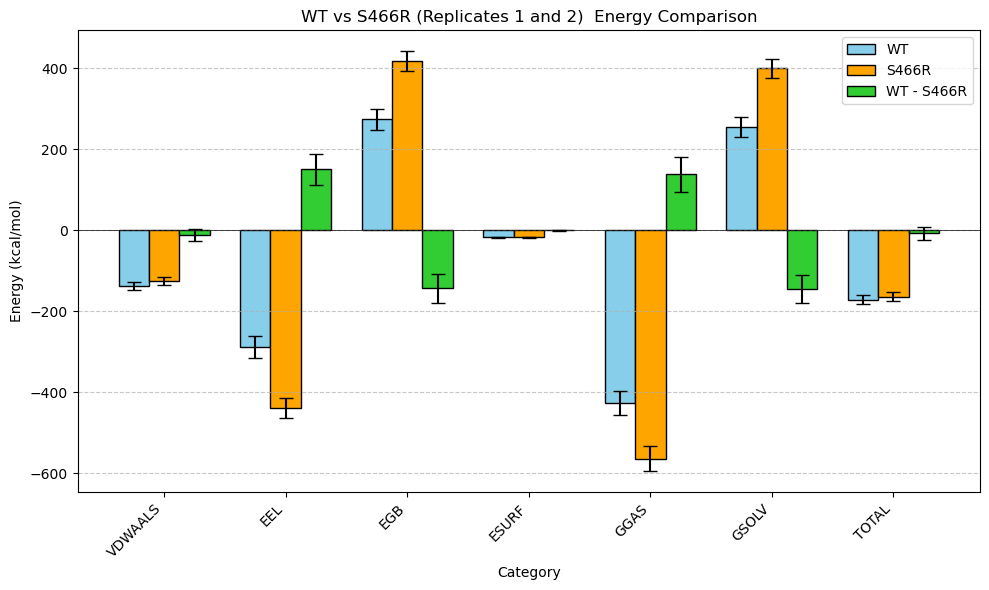

In [19]:
wt_combined_df_t = wt_combined_df.transpose()
S466R_combined_df_t = S466R_combined_df.transpose()

# Find global min and max 
all_data = [
    wt_combined_df_t.values,
    S466R_combined_df_t.values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

# Verify that dfs have the same index
if not wt_combined_df_t.index.equals(S466R_combined_df_t.index):
    raise ValueError("Indices of wt_combined_df_t and S466R_combined_df_t do not match!")


diff_df = pd.DataFrame({
    'mean': wt_combined_df_t['mean'] - S466R_combined_df_t['mean'],
    'std': np.sqrt(wt_combined_df_t['std']**2 + S466R_combined_df_t['std']**2)
}, index=wt_combined_df_t.index)

fig, ax = plt.subplots(figsize=(10, 6))

labels = wt_combined_df_t.index  
x = np.arange(len(labels))  # Positions for bar groups
width = 0.25

# Plot WT bars
ax.bar(x - width, wt_combined_df_t['mean'], width, yerr=wt_combined_df_t['std'], 
       capsize=5, color='skyblue', edgecolor='black', label='WT')

# Plot S466R bars
ax.bar(x, S466R_combined_df_t['mean'], width, yerr=S466R_combined_df_t['std'], 
       capsize=5, color='orange', edgecolor='black', label='S466R')

# Plot difference (WT - S466R) bars
ax.bar(x + width, diff_df['mean'], width, yerr=diff_df['std'], 
       capsize=5, color='limegreen', edgecolor='black', label='WT - S466R')

ax.set_title('WT vs S466R (Replicates 1 and 2)  Energy Comparison')
ax.set_xlabel('Category')
ax.set_ylabel('Energy (kcal/mol)')
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha='right')
ax.grid(True, axis='y', linestyle='--', alpha=0.7)
ax.axhline(0, color='black', linewidth=0.5)
ax.legend()

plt.tight_layout()

In [20]:
wt_combined_df

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-137.768796,-289.567532,273.126104,-18.365023,-427.336244,254.760951,-172.575176
std,9.984252,27.278466,25.747698,1.298792,30.623010,25.194886,11.030096


In [21]:
S466R_combined_df

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-125.092111,-439.435080,417.139701,-17.393458,-564.527071,399.746203,-164.780958
std,9.936660,25.801514,24.259482,1.192004,30.419044,23.791751,11.347652


In [22]:
diff_df

,mean,std
VDWAALS,-12.676685,14.086252
EEL,149.867548,37.547741
EGB,-144.013596,35.376071
ESURF,-0.971565,1.762877
GGAS,137.190827,43.163491
GSOLV,-144.985251,34.652989
TOTAL,-7.794218,15.825051


#### Interpretation


## Residue decomposition

### Load data

In [23]:
def load_decompenergy(mut):
    dfs = []
    for rep in range(1, 4):
        energyfile = f'../../data/1bf5/{mut}/rep{rep}/analysis/006_gbsa/FINAL_ENERGY_DECOMP.csv'
        with open(energyfile, 'r') as f:
            lines = f.readlines()

        # Find the start and end indices for the section
        start_idx = None
        end_idx = None
        for i, line in enumerate(lines):
            line_clean = line.strip()
            if "DELTAS:" in line_clean:
                start_idx = i + 2  # Skip "DELTAS:" and "Total Decomposition Contribution (TDC)"
                continue
            if start_idx is not None and "Sidechain Decomposition Contribution" in line_clean:
                end_idx = i  
                break

        # Extract the lines between start_idx and end_idx
        data_lines = lines[start_idx:end_idx]
        data_string = ''.join(data_lines)

        df = pd.read_csv(StringIO(data_string))
        dfs.append(df)

    return dfs

In [24]:
wt_decomp_dfs = load_decompenergy('wt')
S466R_decomp_dfs = load_decompenergy('S466R')

In [25]:
wt_decomp_dfs[0].head()

,Frame #,Residue,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL
0,1000,L:A:MET:190,0.0,-0.36,-0.97,0.92,-0.02,-0.44
1,1000,L:A:PRO:191,0.0,-0.29,-0.50,0.48,-0.02,-0.32
2,1000,L:A:THR:192,0.0,-1.20,-0.89,0.56,-0.52,-2.05
3,1000,L:A:HIE:193,0.0,-0.26,-0.82,0.82,0.00,-0.27
4,1000,L:A:VAL:199,0.0,-0.04,0.04,-0.03,0.00,-0.04


In [26]:
S466R_decomp_dfs[0].head()

,Frame #,Residue,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL
0,1000,L:A:MET:190,0.0,-0.06,0.21,-0.19,0.00,-0.05
1,1000,L:A:PRO:191,0.0,-0.22,0.21,-0.17,-0.01,-0.19
2,1000,L:A:THR:192,0.0,-0.47,0.87,-0.75,-0.15,-0.49
3,1000,L:A:HIE:193,0.0,-0.17,-0.56,0.57,0.00,-0.16
4,1000,L:A:LYS:201,0.0,-0.46,-36.70,35.88,-0.11,-1.38


Break down the residue identifiers and adjust the residue numbers.

In [27]:
for df in (wt_decomp_dfs + S466R_decomp_dfs):
    split_cols = df["Residue"].str.split(":", expand=True)
    df["compound"] = split_cols[0]
    df["chain"] = split_cols[1]
    df["resnm"] = split_cols[2]
    df["resid"] = split_cols[3]
    df["resid_adj"] = np.where(df["chain"].isin(["A", "B"]), (df['resid'].astype(int)+ 135).astype(str), df['resid'])


In [28]:
wt_decomp_dfs[0].head()

,Frame #,Residue,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL,compound,chain,resnm,resid,resid_adj
0,1000,L:A:MET:190,0.0,-0.36,-0.97,0.92,-0.02,-0.44,L,A,MET,190,325
1,1000,L:A:PRO:191,0.0,-0.29,-0.50,0.48,-0.02,-0.32,L,A,PRO,191,326
2,1000,L:A:THR:192,0.0,-1.20,-0.89,0.56,-0.52,-2.05,L,A,THR,192,327
3,1000,L:A:HIE:193,0.0,-0.26,-0.82,0.82,0.00,-0.27,L,A,HIE,193,328
4,1000,L:A:VAL:199,0.0,-0.04,0.04,-0.03,0.00,-0.04,L,A,VAL,199,334


### By replicate

In [29]:
def decomp_summary (dfs):
    dfs_decomp_summary = []

    # Energy columns to summarize
    energy_columns = ['van der Waals', 'Electrostatic', 
        'Polar Solvation', 'Non-Polar Solv.', 'TOTAL'
    ]

    for df in dfs:
        # Group by residue identifiers
        grouped = df.groupby(['Residue', 'compound', 'chain', 'resnm', 'resid', 'resid_adj'])
        
        # Compute mean, std, and sem for energy columns
        desc = pd.concat([
            grouped[energy_columns].mean().rename(columns=lambda x: f'{x}_mean'),
            grouped[energy_columns].std().rename(columns=lambda x: f'{x}_std'),
        ], axis=1)
        
        # Reset index to make Residue, compound, chain, resnm, resid regular columns
        desc = desc.reset_index()
        
        # Append to summary list
        dfs_decomp_summary.append(desc)
    return dfs_decomp_summary

In [30]:
wt_decomp_summary = decomp_summary(wt_decomp_dfs)
S466R_decomp_summary = decomp_summary(S466R_decomp_dfs)

In [31]:
wt_decomp_summary[0].head()

,Residue,compound,chain,resnm,resid,resid_adj,van der Waals_mean,Electrostatic_mean,Polar Solvation_mean,Non-Polar Solv._mean,TOTAL_mean,van der Waals_std,Electrostatic_std,Polar Solvation_std,Non-Polar Solv._std,TOTAL_std
0,L:A:ARG:243,L,A,ARG,243,378,-0.812884,-33.997984,32.926407,-0.118253,-2.002874,0.551134,0.639254,0.540212,0.030703,0.507411
1,L:A:ARG:283,L,A,ARG,283,418,-0.357176,-28.120120,27.481786,-0.140250,-1.135699,0.632486,4.142819,3.857355,0.187710,0.905507
2,L:A:ASN:285,L,A,ASN,285,420,-1.392754,-0.532275,0.499192,-0.204701,-1.630489,1.021933,1.165361,1.007648,0.147839,1.219752
3,L:A:ASN:325,L,A,ASN,325,460,-2.883244,-1.444401,1.438104,-0.609890,-3.499361,0.784771,0.292259,0.247205,0.060625,0.747075
4,L:A:GLN:205,L,A,GLN,205,340,-1.156737,-1.226048,1.056826,-0.306437,-1.632345,0.731263,0.387292,0.272394,0.079696,0.696818


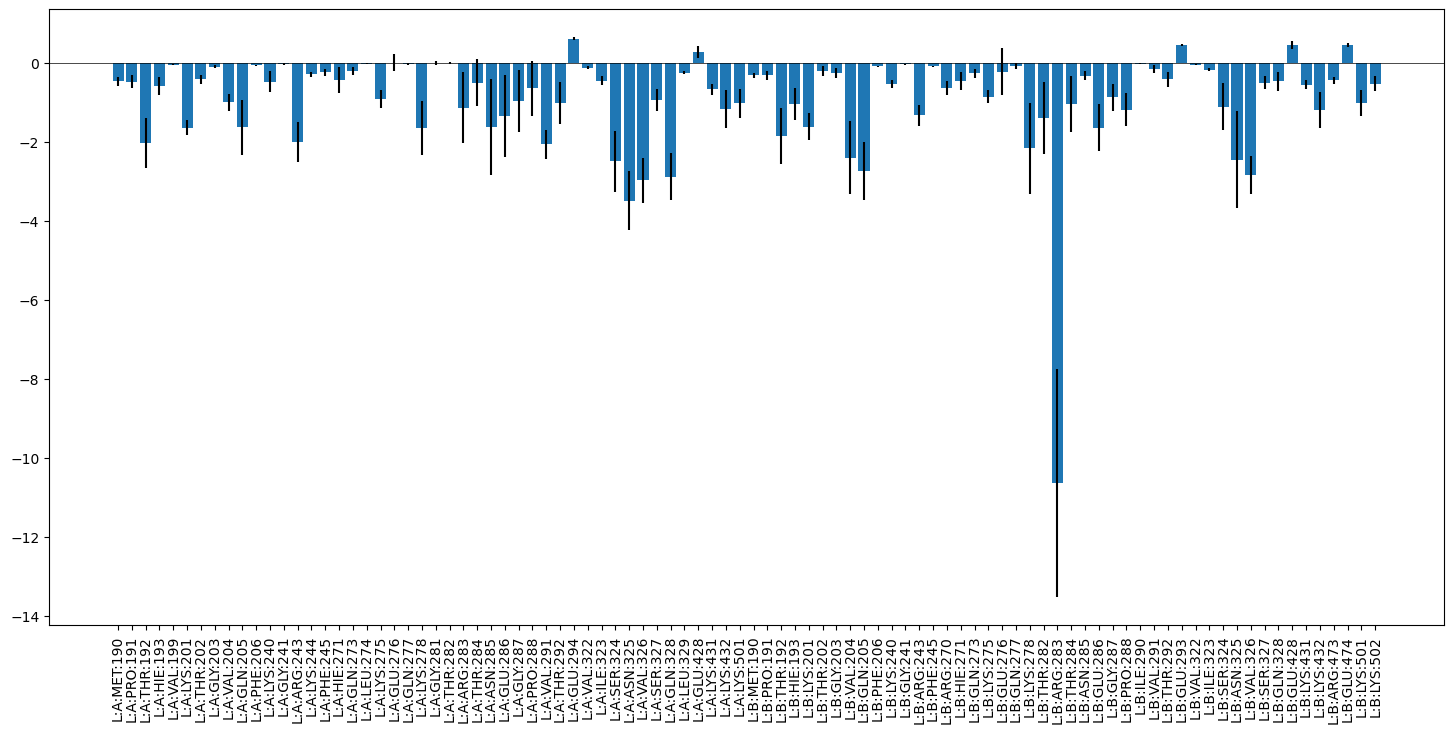

In [32]:
df = wt_decomp_summary[0][wt_decomp_summary[0]["compound"] == "L"].sort_values(by=["chain", "resid"], ascending=True)
plt.figure(figsize=(18, 8))
plt.bar(df['Residue'], df['TOTAL_mean'], yerr=df['TOTAL_std'])

plt.axhline(0, color='black', linewidth=0.5)
plt.xticks(rotation=90)
plt.show()

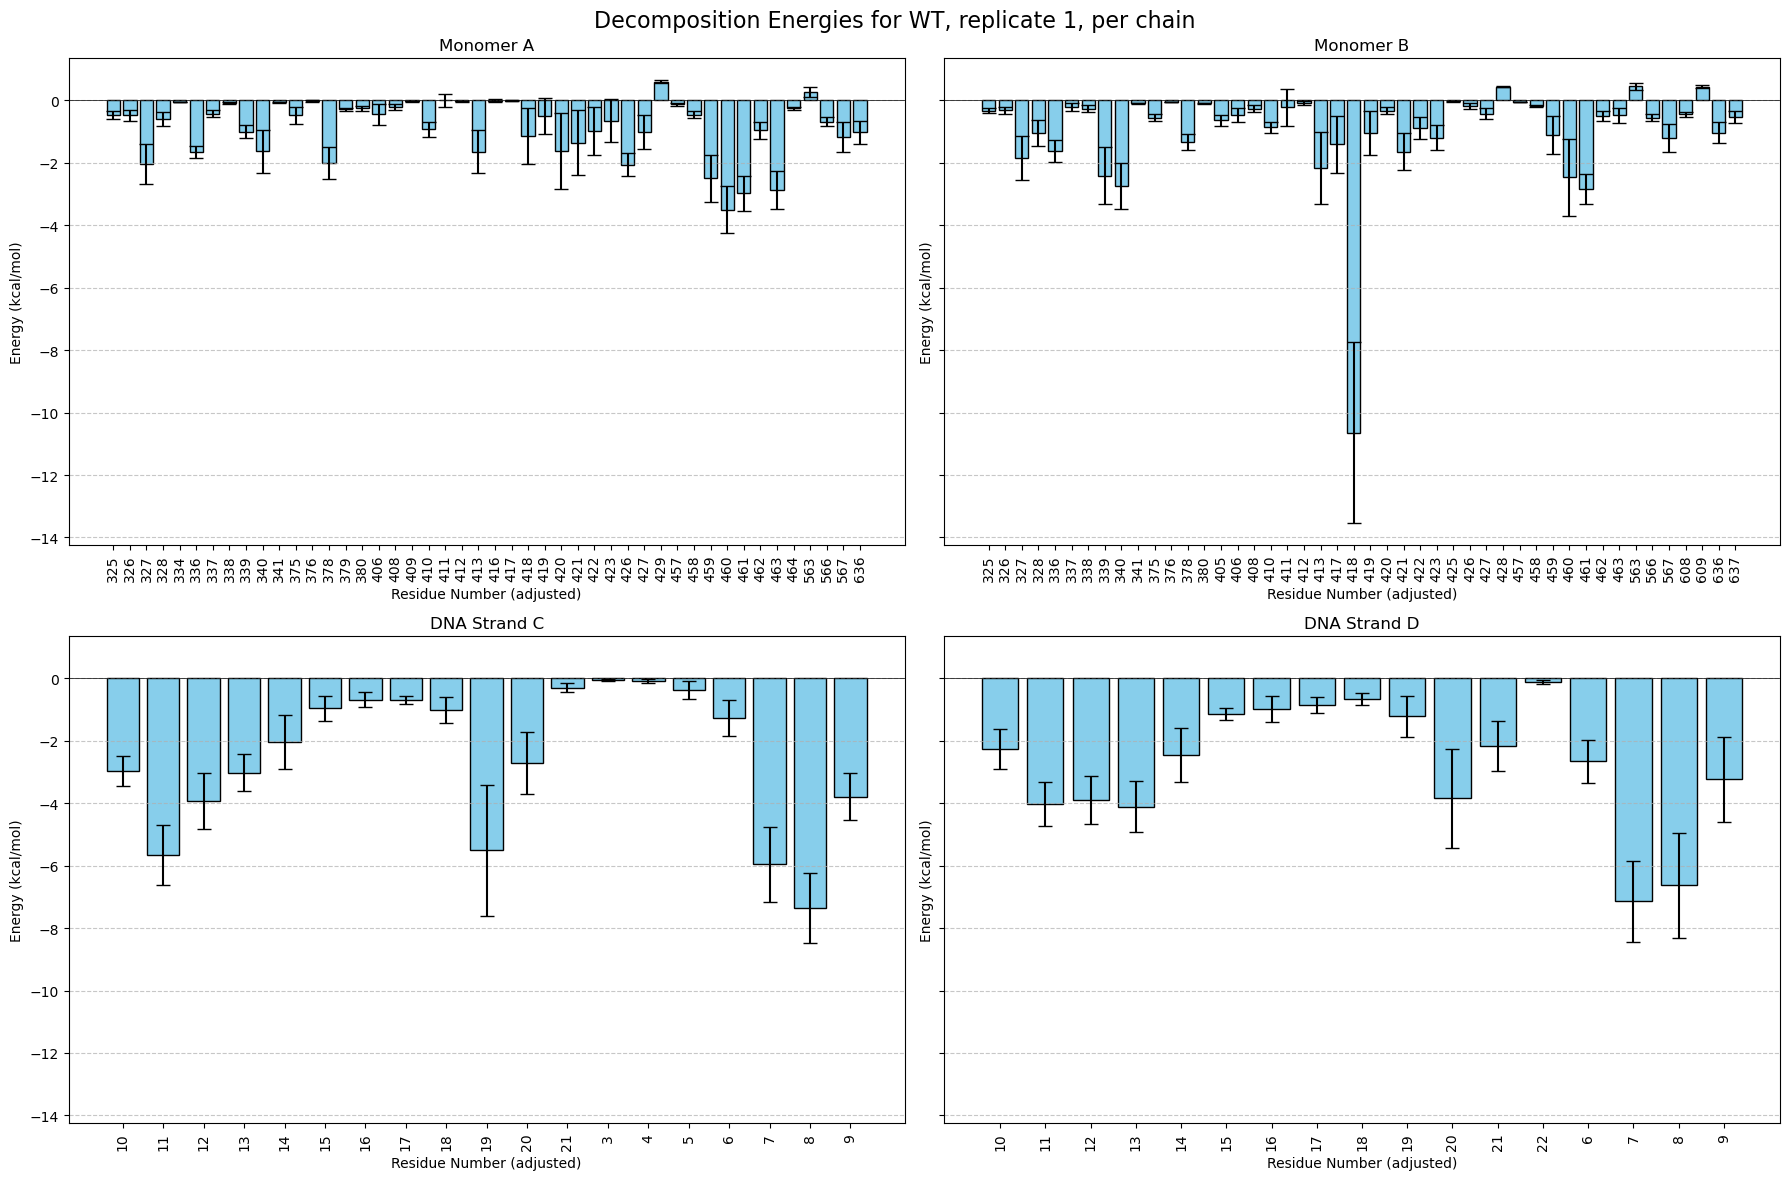

In [33]:
df_chainA = wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_chainB = wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)
df_chainC = wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "C"].sort_values(by=["resid_adj"], ascending=True)
df_chainD = wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "D"].sort_values(by=["resid_adj"], ascending=True)


# Find global min and max
all_data = [
    df_chainA['TOTAL_mean'].values,
    df_chainB['TOTAL_mean'].values,
    df_chainC['TOTAL_mean'].values,
    df_chainD['TOTAL_mean'].values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (df_chainA, ax1, 'Monomer A'),
    (df_chainB, ax2, 'Monomer B'),
    (df_chainC, ax3, 'DNA Strand C'),
    (df_chainD, ax4, 'DNA Strand D'),
]

for df, ax, title in plots:
    ax.bar(df["resid_adj"], df['TOTAL_mean'], yerr=df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True)
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for WT, replicate 1, per chain', fontsize=16)

plt.tight_layout()
plt.show()

In [34]:
wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "A"].sort_values('resid_adj')['resid_adj'].unique() 

array(['325', '326', '327', '328', '334', '336', '337', '338', '339',
       '340', '341', '375', '376', '378', '379', '380', '406', '408',
       '409', '410', '411', '412', '413', '416', '417', '418', '419',
       '420', '421', '422', '423', '426', '427', '429', '457', '458',
       '459', '460', '461', '462', '463', '464', '563', '566', '567',
       '636'], dtype=object)

In [35]:
wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "B"].sort_values('resid_adj')['resid_adj'].unique() 

array(['325', '326', '327', '328', '336', '337', '338', '339', '340',
       '341', '375', '376', '378', '380', '405', '406', '408', '410',
       '411', '412', '413', '417', '418', '419', '420', '421', '422',
       '423', '425', '426', '427', '428', '457', '458', '459', '460',
       '461', '462', '463', '563', '566', '567', '608', '609', '636',
       '637'], dtype=object)

In [36]:
wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "A"].sort_values('resid_adj')['resid_adj'].unique()  == wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "B"].sort_values('resid_adj')['resid_adj'].unique() 

array([ True,  True,  True,  True, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False])

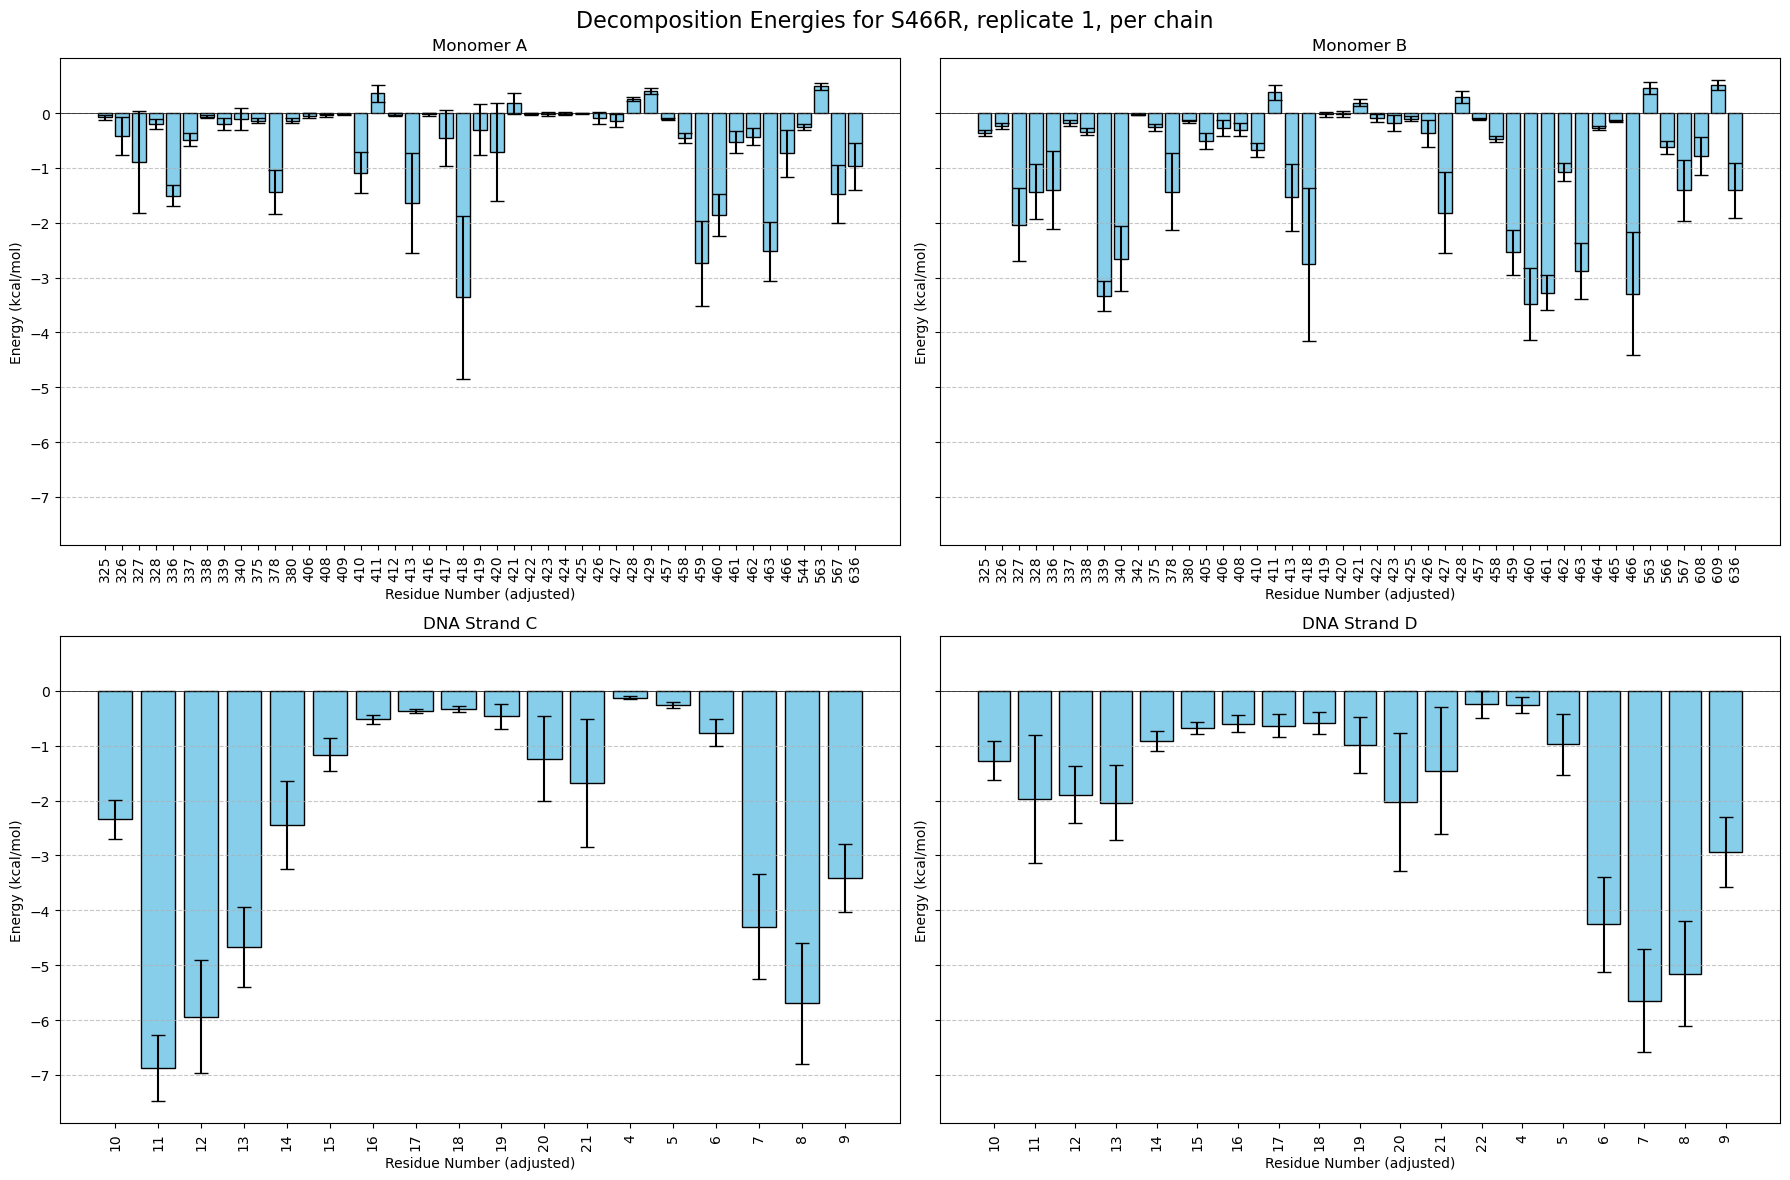

In [37]:

df_chainA = S466R_decomp_summary[0][S466R_decomp_summary[0]["chain"] == "A"].sort_values(by=["resid"], ascending=True)
df_chainB = S466R_decomp_summary[0][S466R_decomp_summary[0]["chain"] == "B"].sort_values(by=["resid"], ascending=True)
df_chainC = S466R_decomp_summary[0][S466R_decomp_summary[0]["chain"] == "C"].sort_values(by=["resid"], ascending=True)
df_chainD = S466R_decomp_summary[0][S466R_decomp_summary[0]["chain"] == "D"].sort_values(by=["resid"], ascending=True)


# Find global min and max
all_data = [
    df_chainA['TOTAL_mean'].values,
    df_chainB['TOTAL_mean'].values,
    df_chainC['TOTAL_mean'].values,
    df_chainD['TOTAL_mean'].values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (df_chainA, ax1, 'Monomer A'),
    (df_chainB, ax2, 'Monomer B'),
    (df_chainC, ax3, 'DNA Strand C'),
    (df_chainD, ax4, 'DNA Strand D'),
]

for df, ax, title in plots:
    ax.bar(df['resid_adj'], df['TOTAL_mean'], yerr=df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True)
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for S466R, replicate 1, per chain', fontsize=16)

plt.tight_layout()
plt.show()

There might be significant differences between monomers for corresponding residues, that is, residues with the same number. Also note that MMPBSA filtered out different residues in each monomer, likely due to their energy values close to zero. 
It is challenging to draw conclusions from the separate replicate data and it is advisable to aggregate it.

### By mutation (combining replicates)

In [38]:
def combine_decomp(dfs):
    
    df = pd.concat(dfs)

    energy_terms = ['van der Waals', 'Electrostatic', 
        'Polar Solvation', 'Non-Polar Solv.', 'TOTAL'
    ]
    
    # Columns for means and standard deviations
    mean_cols = [f"{term}_mean" for term in energy_terms]
    std_cols = [f"{term}_std" for term in energy_terms]
    
    # Group by residue identifiers
    group_cols = ['Residue', 'compound', 'chain', 'resnm', 'resid', 'resid_adj']
    df_grouped = df.groupby(group_cols)
    
    result_data = []
    
    # Process each group (residue)
    for name, group in df_grouped:
        # Dictionary to store results for this group
        group_result = dict(zip(group_cols, name))
        
        # Calculate mean and pooled std for each energy term
        for mean_col, std_col in zip(mean_cols, std_cols):
            # Mean
            combined_mean = group[mean_col].mean()
            
            # Pooled standard deviation
            stds = group[std_col]
            variances = [s**2 for s in stds]
            pooled_variance = np.mean(variances)  # Average variances
            pooled_std = np.sqrt(pooled_variance) if pooled_variance > 0 else 0.0
            
            group_result[mean_col] = combined_mean
            group_result[std_col] = pooled_std
        
        result_data.append(group_result)
    
    combined_df = pd.DataFrame(result_data)
    
    # Reorder columns to match input structure
    output_cols = group_cols + [col for term in energy_terms for col in [f"{term}_mean", f"{term}_std"]]
    combined_df = combined_df[output_cols]
    
    return combined_df

In [39]:
wt_decomp_combined_df = combine_decomp(wt_decomp_summary)
S466R_decomp_combined_df = combine_decomp(S466R_decomp_summary)

In [40]:
wt_decomp_combined_df.head()

,Residue,compound,chain,resnm,resid,resid_adj,van der Waals_mean,van der Waals_std,Electrostatic_mean,Electrostatic_std,Polar Solvation_mean,Polar Solvation_std,Non-Polar Solv._mean,Non-Polar Solv._std,TOTAL_mean,TOTAL_std
0,L:A:ALA:280,L,A,ALA,280,415,-0.036178,0.029370,-0.066886,0.380156,0.069052,0.356568,-0.000709,0.007166,-0.034481,0.045270
1,L:A:ARG:243,L,A,ARG,243,378,-0.780729,0.564764,-33.489541,0.633727,32.407764,0.549420,-0.135542,0.034170,-1.998114,0.521936
2,L:A:ARG:283,L,A,ARG,283,418,-1.408623,1.126137,-28.401906,3.768551,27.720366,3.498618,-0.309102,0.238257,-2.399155,1.443181
3,L:A:ASN:279,L,A,ASN,279,414,-0.045719,0.027597,0.487874,0.477485,-0.449331,0.451858,-0.000240,0.004210,-0.007495,0.039454
4,L:A:ASN:285,L,A,ASN,285,420,-1.347026,0.839330,-0.576391,0.827235,0.626653,0.743328,-0.206131,0.141764,-1.502884,0.974604


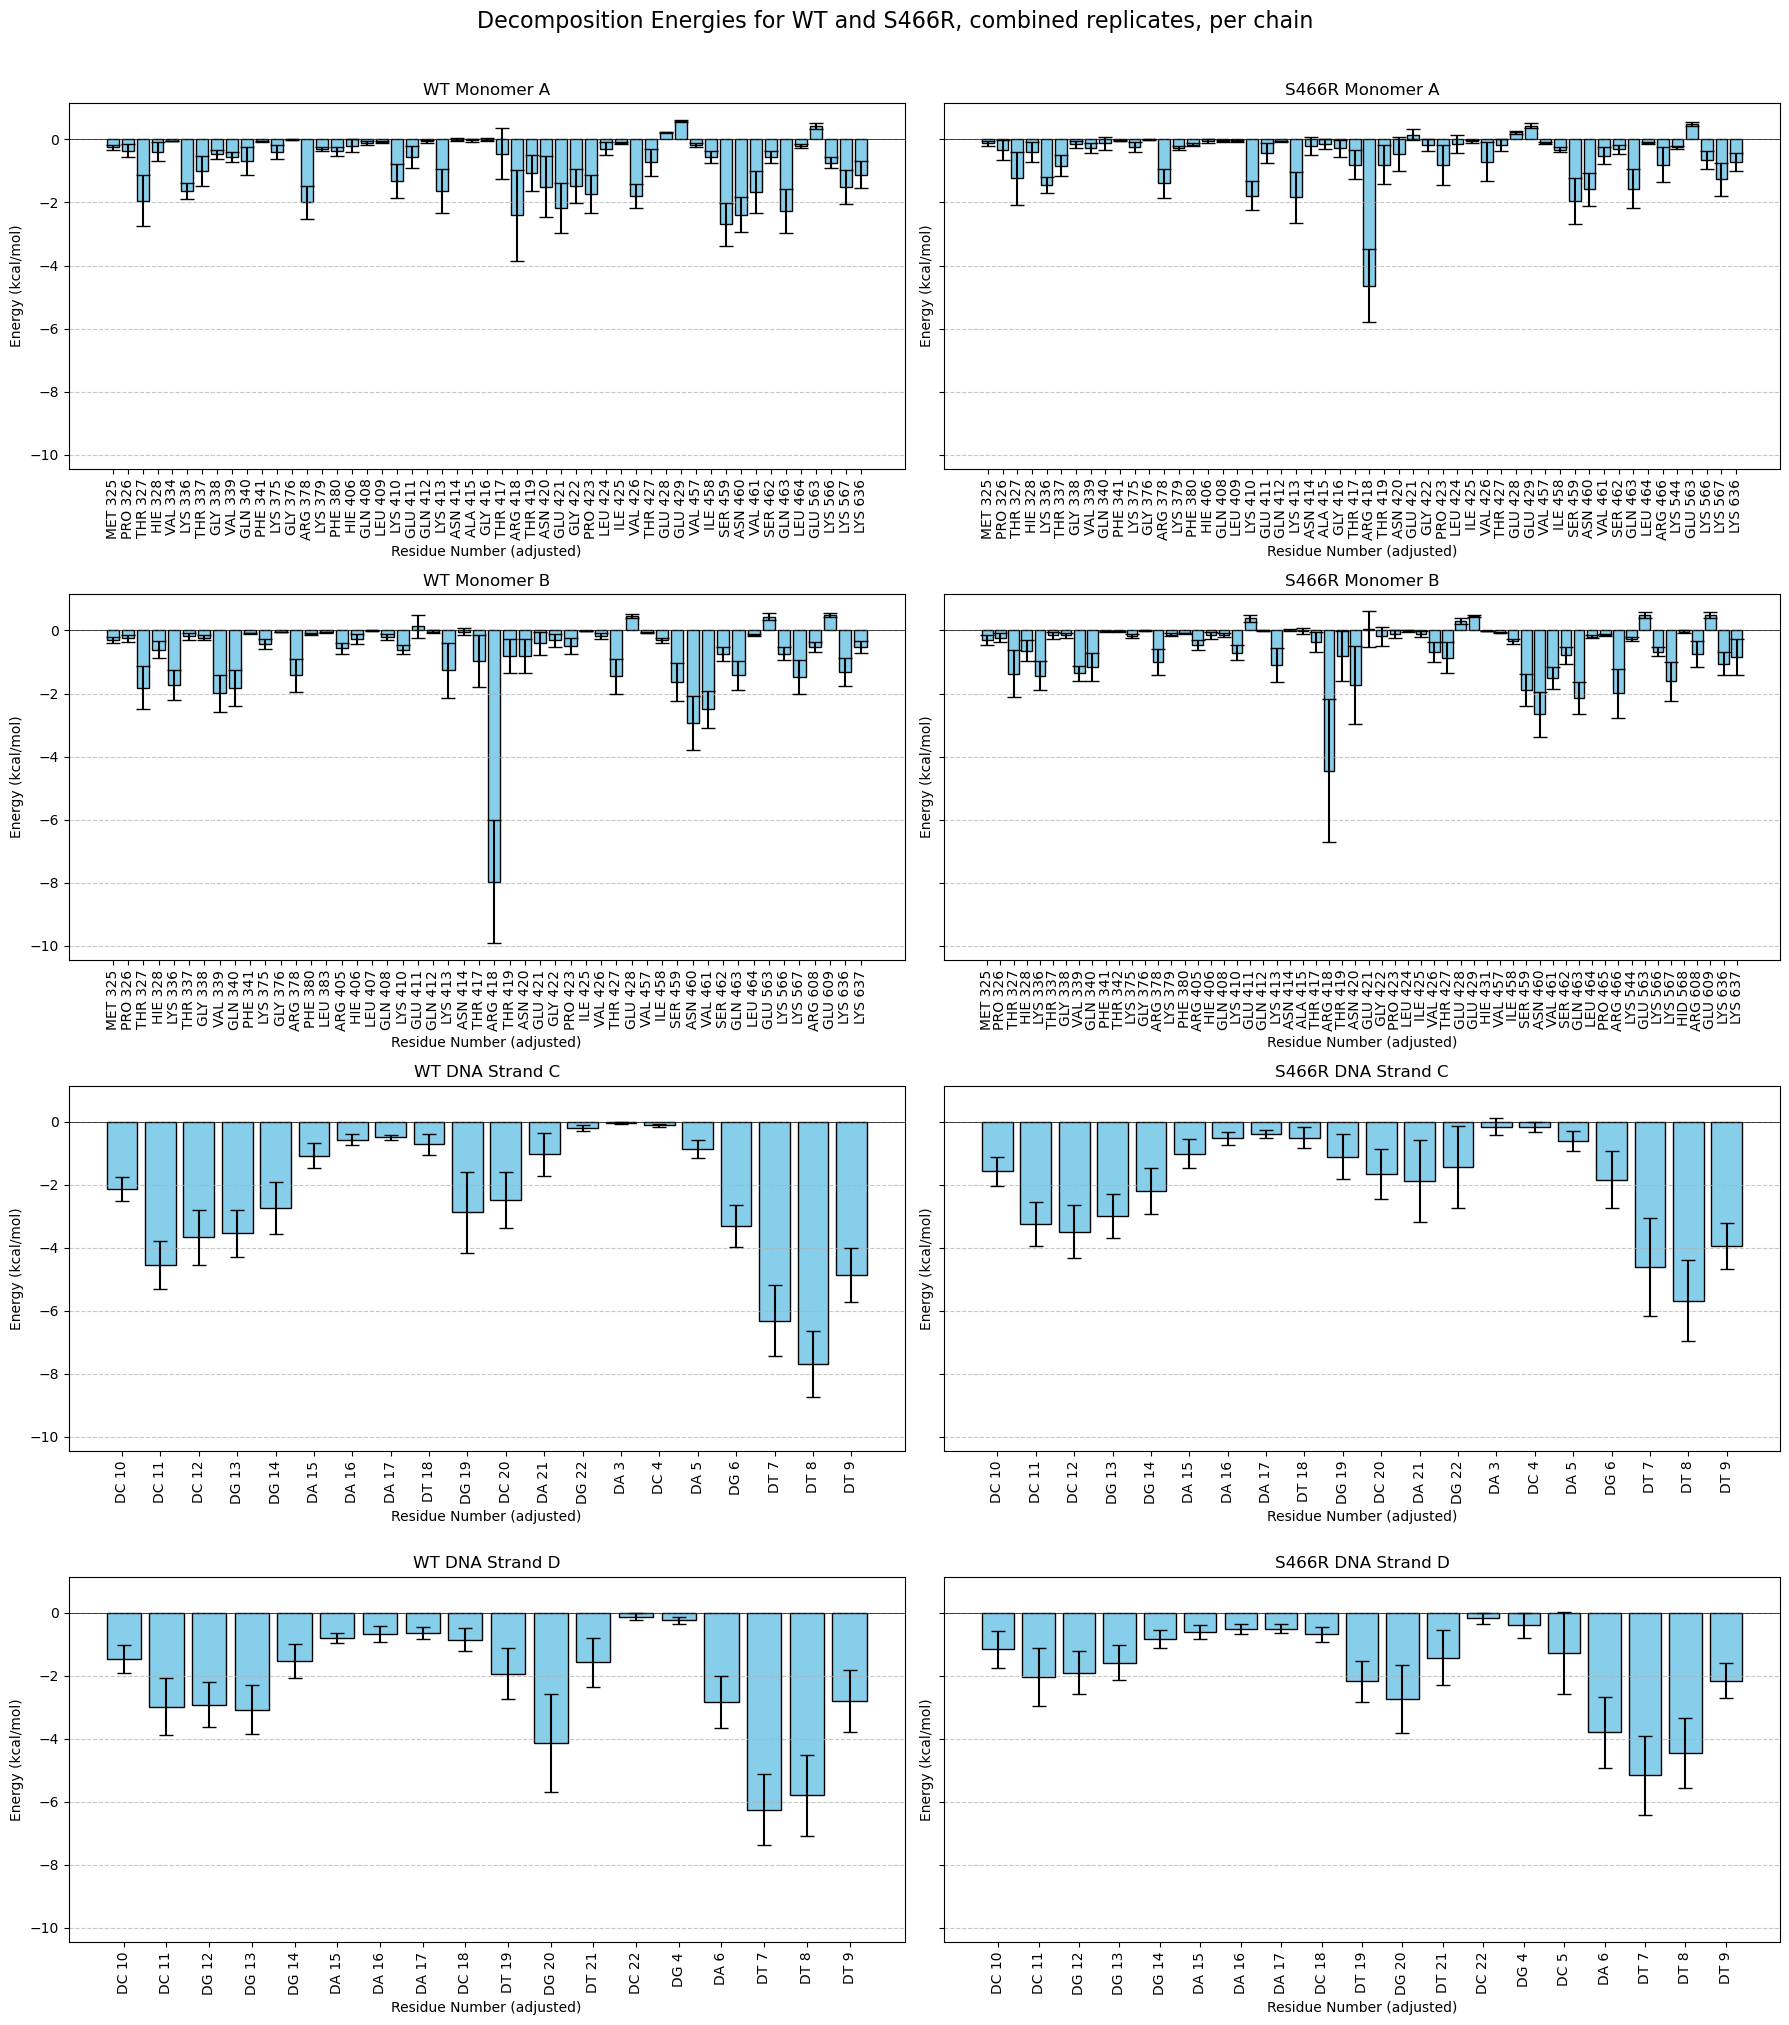

In [41]:
df_wt_monoA = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_monoA = S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)

df_wt_monoB = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_monoB = S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)

df_wt_dnaC = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "C"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_dnaC = S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "C"].sort_values(by=["resid_adj"], ascending=True)

df_wt_dnaD = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "D"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_dnaD = S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "D"].sort_values(by=["resid_adj"], ascending=True)

# Find global min and max
all_data = [
    df_wt_monoA['TOTAL_mean'].values,
    df_S466R_monoA['TOTAL_mean'].values,
    df_wt_monoB['TOTAL_mean'].values,
    df_S466R_monoB['TOTAL_mean'].values,
    df_wt_dnaC['TOTAL_mean'].values,
    df_S466R_dnaC['TOTAL_mean'].values,
    df_wt_dnaD['TOTAL_mean'].values,
    df_S466R_dnaD['TOTAL_mean'].values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(4, 2, figsize=(18, 20), sharey=True)
ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8 = axes.flatten()

plots = [
    (df_wt_monoA, ax1, 'WT Monomer A'),
    (df_S466R_monoA, ax2, 'S466R Monomer A'),
    (df_wt_monoB, ax3, 'WT Monomer B'),
    (df_S466R_monoB, ax4, 'S466R Monomer B'),
    (df_wt_dnaC, ax5, 'WT DNA Strand C'),   
    (df_S466R_dnaC, ax6, 'S466R DNA Strand C'),
    (df_wt_dnaD, ax7, 'WT DNA Strand D'),
    (df_S466R_dnaD, ax8, 'S466R DNA Strand D'),
]

for df, ax, title in plots:
    ax.bar(df['resid_adj'], df['TOTAL_mean'], yerr=df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True,)
    ax.set_xticks(df['resid_adj'])
    ax.set_xticklabels([f"{resnm} {resid}" for resnm, resid in zip(df['resnm'], df['resid_adj'])])
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for WT and S466R, combined replicates, per chain', fontsize=16, y=1.01)

plt.tight_layout()
plt.show()

Zoom in on the mutated residue.

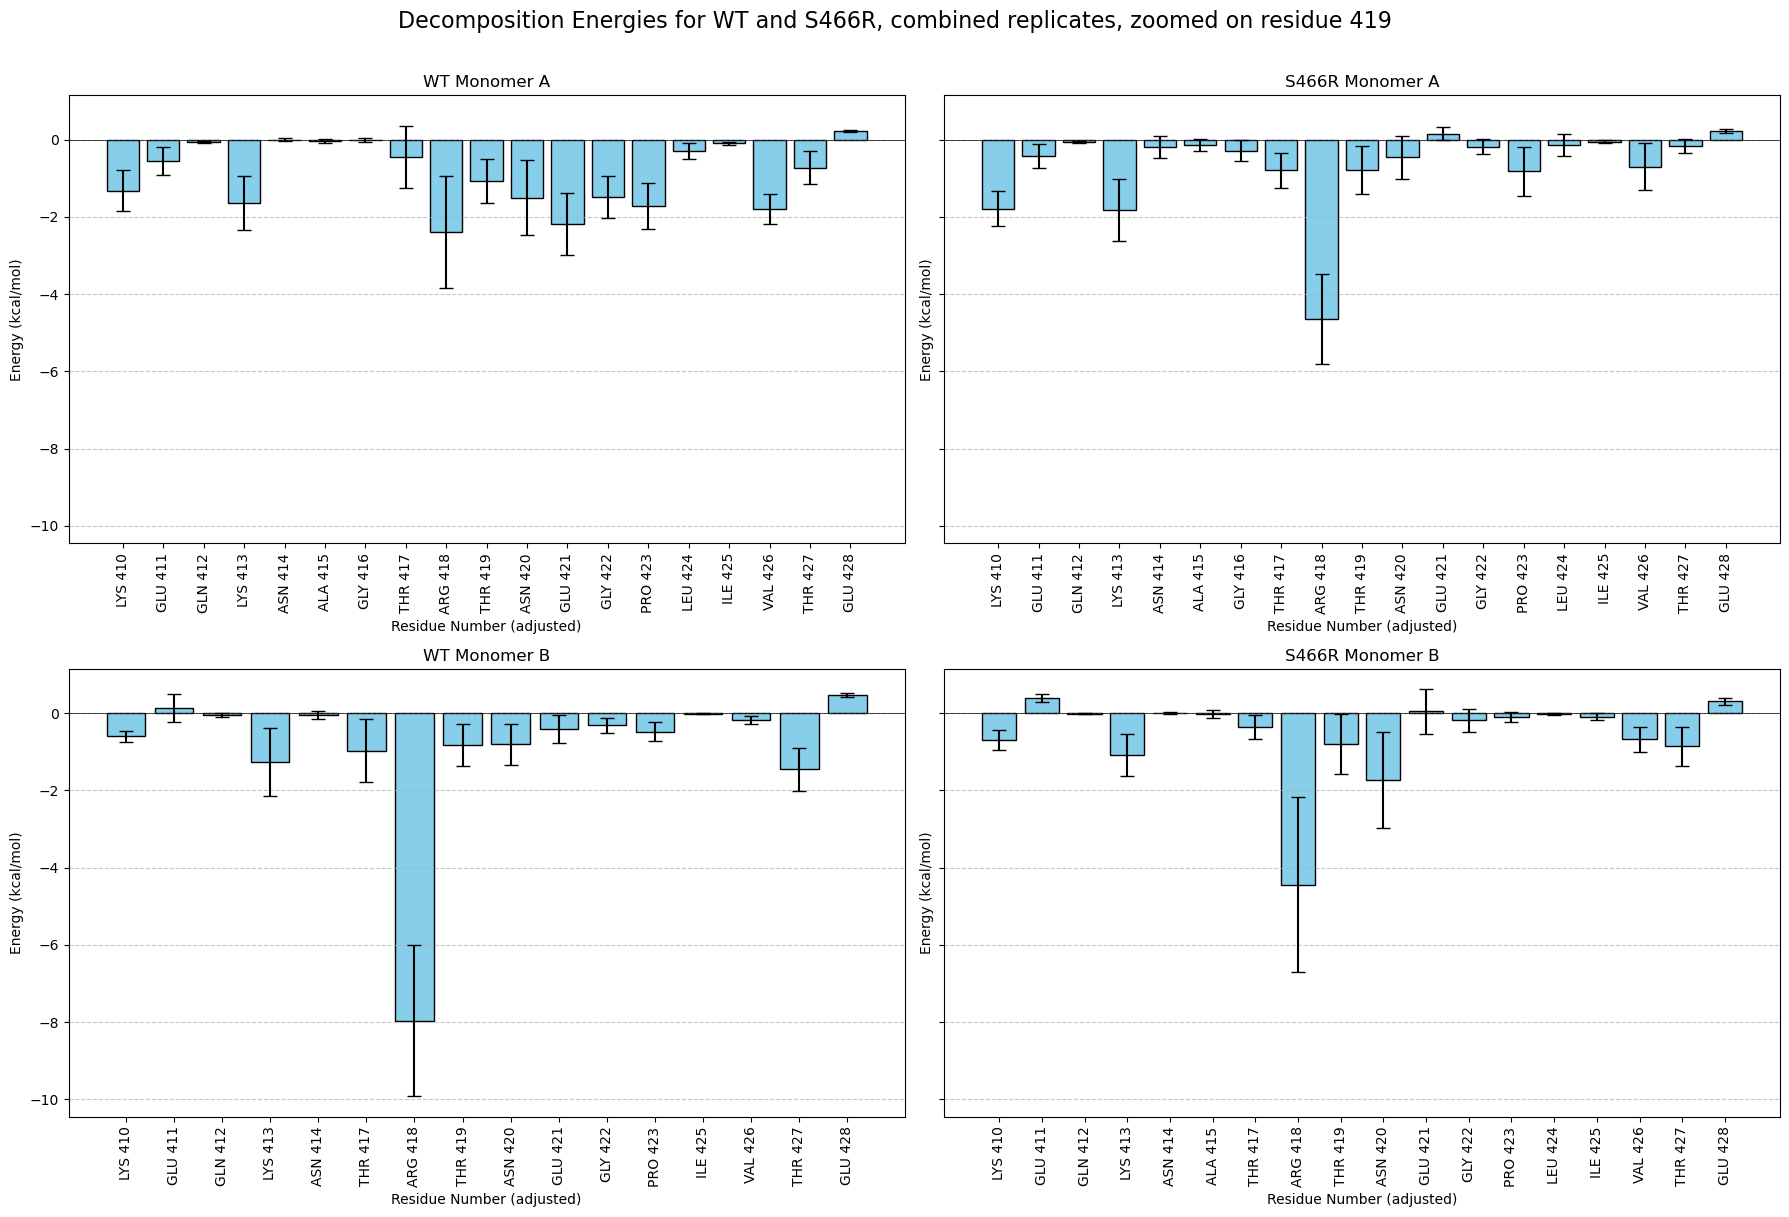

In [42]:
df_wt_monoA = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_monoA = S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)

df_wt_monoB = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_monoB = S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)

# Find global min and max
all_data = [
    df_wt_monoA['TOTAL_mean'].values,
    df_S466R_monoA['TOTAL_mean'].values,
    df_wt_monoB['TOTAL_mean'].values,
    df_S466R_monoB['TOTAL_mean'].values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (df_wt_monoA, ax1, 'WT Monomer A'),
    (df_S466R_monoA, ax2, 'S466R Monomer A'),
    (df_wt_monoB, ax3, 'WT Monomer B'),
    (df_S466R_monoB, ax4, 'S466R Monomer B'),
]

for df, ax, title in plots:
    filtered_df = df[(df['resid_adj'].astype(int) > 409) & (df['resid_adj'].astype(int) < 429)]
    ax.bar(filtered_df['resid_adj'], filtered_df['TOTAL_mean'], yerr=filtered_df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True,)
    ax.set_xticks(filtered_df['resid_adj'])
    ax.set_xticklabels([f"{resnm} {resid}" for resnm, resid in zip(filtered_df['resnm'], filtered_df['resid_adj'])])
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for WT and S466R, combined replicates, zoomed on residue 419', fontsize=16, y=1.01)

plt.tight_layout()
plt.show()

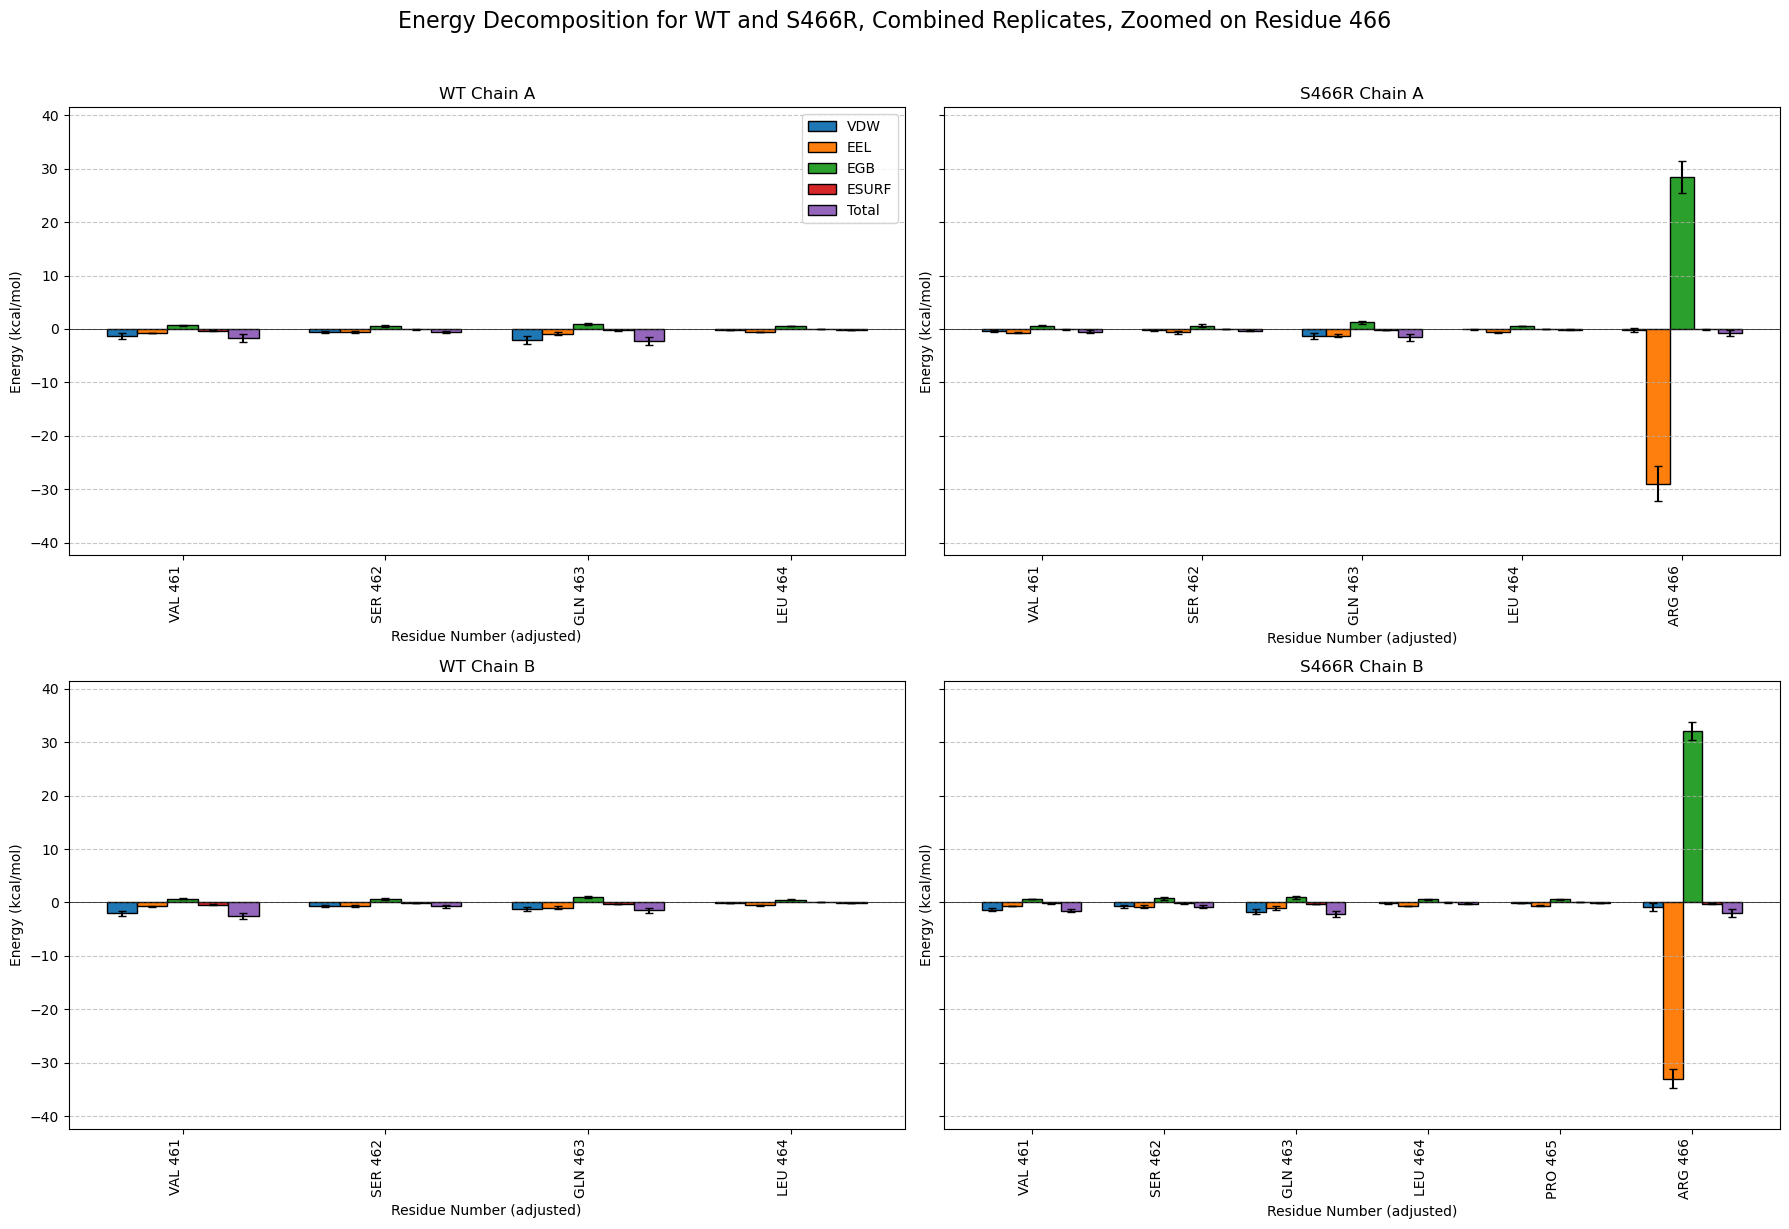

In [43]:
df_wt_monoA = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_monoA = S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)

df_wt_monoB = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_monoB = S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)

# Define energy terms and their corresponding std columns
energy_terms = [
    'van der Waals_mean', 'Electrostatic_mean', 'Polar Solvation_mean',
    'Non-Polar Solv._mean', 'TOTAL_mean'
]
std_terms = [
    'van der Waals_std', 'Electrostatic_std', 'Polar Solvation_std',
    'Non-Polar Solv._std', 'TOTAL_std'
]

# Find global min and max across all energy terms
all_data = []
for df in [df_wt_monoA, df_S466R_monoA, df_wt_monoB, df_S466R_monoB]:
    for term in energy_terms:
        all_data.append(df[term].values)
global_min = min([np.nanmin(data) for data in all_data]) * 1.1  # Add 10% buffer
global_max = max([np.nanmax(data) for data in all_data]) * 1.1  # Add 10% buffer

# Create figure and subplots
fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

# Define plots
plots = [
    (df_wt_monoA, ax1, 'WT Chain A'),
    (df_S466R_monoA, ax2, 'S466R Chain A'),
    (df_wt_monoB, ax3, 'WT Chain B'),
    (df_S466R_monoB, ax4, 'S466R Chain B'),
]

# Plotting parameters
n_terms = len(energy_terms)  # Number of energy terms (5)
bar_width = 0.15  # Width of each bar
labels = ['VDW', 'EEL', 'EGB', 'ESURF', 'Total']  # Short labels for legend

for df, ax, title in plots:
    # Filter for residues in the range 456-470
    filtered_df = df[(df['resid_adj'].astype(int) > 460) & (df['resid_adj'].astype(int) < 470)]
    
    # Get residue positions and labels
    residues = filtered_df['resid_adj'].values
    res_labels = [f"{resnm} {resid}" for resnm, resid in zip(filtered_df['resnm'], filtered_df['resid_adj'])]
    n_residues = len(residues)
    
    # Set x positions for bars
    x = np.arange(n_residues)  # Base positions for residues
    for i, (term, std, label) in enumerate(zip(energy_terms, std_terms, labels)):
        # Calculate x positions for this term's bars
        x_pos = x + i * bar_width - (n_terms - 1) * bar_width / 2
        # Plot bars with error bars
        ax.bar(
            x_pos,
            filtered_df[term],
            yerr=filtered_df[std],
            width=bar_width,
            edgecolor='black',
            capsize=3,
            label=label if ax == ax1 else None  # Add legend only on first subplot
        )
    
    # Customize axes
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.set_xticks(x)
    ax.set_xticklabels(res_labels, rotation=90, ha='right')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_ylim(global_min, global_max)  # Set consistent y-limits

# Add legend to the first subplot
ax1.legend(loc='best')

# Add suptitle and adjust layout
plt.suptitle('Energy Decomposition for WT and S466R, Combined Replicates, Zoomed on Residue 466', fontsize=16, y=1.02)

plt.tight_layout()
plt.show()

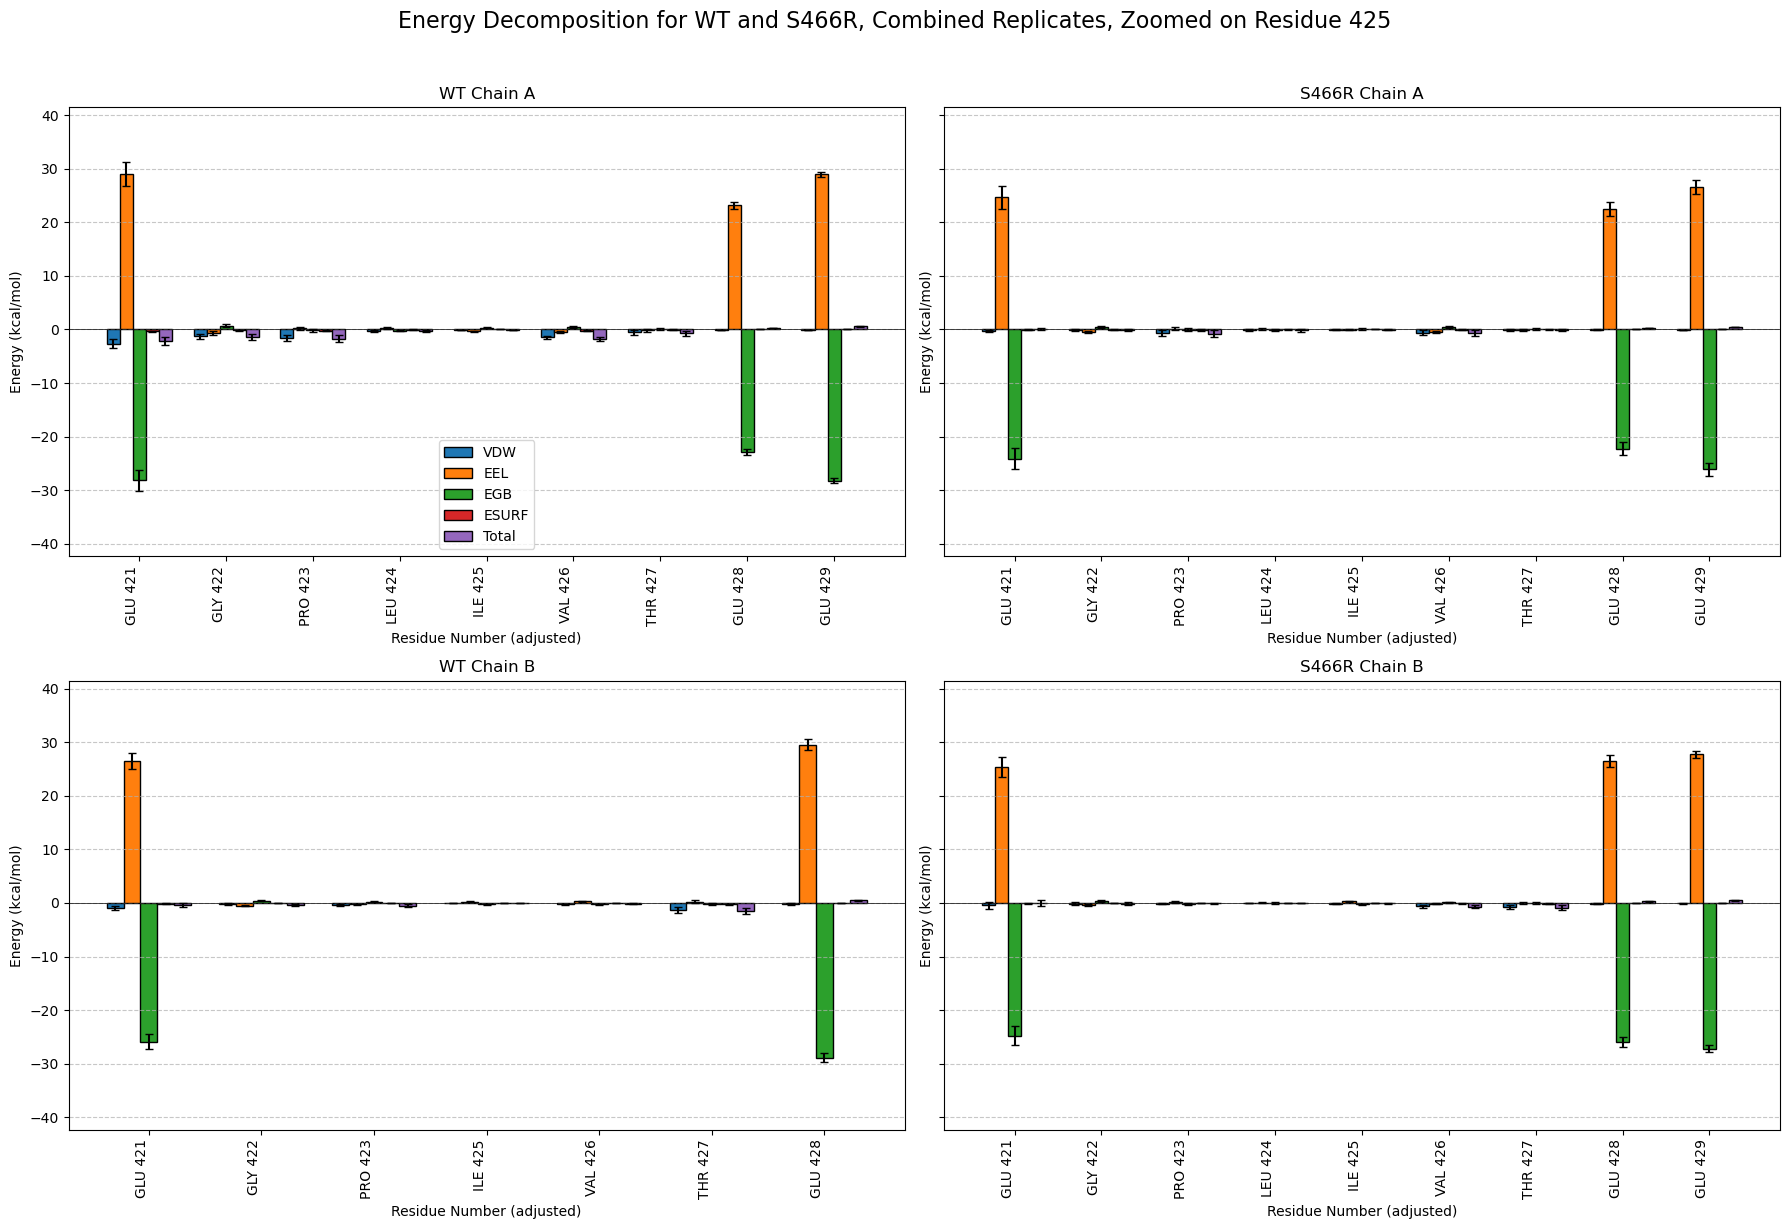

In [44]:

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

# Define plots
plots = [
    (df_wt_monoA, ax1, 'WT Chain A'),
    (df_S466R_monoA, ax2, 'S466R Chain A'),
    (df_wt_monoB, ax3, 'WT Chain B'),
    (df_S466R_monoB, ax4, 'S466R Chain B'),
]

# Plotting parameters
n_terms = len(energy_terms)  # Number of energy terms (5)
bar_width = 0.15  # Width of each bar
labels = ['VDW', 'EEL', 'EGB', 'ESURF', 'Total']  # Short labels for legend

for df, ax, title in plots:
    # Filter for residues in the range 420-430
    filtered_df = df[(df['resid_adj'].astype(int) > 420) & (df['resid_adj'].astype(int) < 430)]
    
    # Get residue positions and labels
    residues = filtered_df['resid_adj'].values
    res_labels = [f"{resnm} {resid}" for resnm, resid in zip(filtered_df['resnm'], filtered_df['resid_adj'])]
    n_residues = len(residues)
    
    # Set x positions for bars
    x = np.arange(n_residues)  # Base positions for residues
    for i, (term, std, label) in enumerate(zip(energy_terms, std_terms, labels)):
        # Calculate x positions for this term's bars
        x_pos = x + i * bar_width - (n_terms - 1) * bar_width / 2
        # Plot bars with error bars
        ax.bar(
            x_pos,
            filtered_df[term],
            yerr=filtered_df[std],
            width=bar_width,
            edgecolor='black',
            capsize=3,
            label=label if ax == ax1 else None  # Add legend only on first subplot
        )
    
    # Customize axes
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.set_xticks(x)
    ax.set_xticklabels(res_labels, rotation=90, ha='right')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_ylim(global_min, global_max)  # Set consistent y-limits

# Add legend to the first subplot
ax1.legend(loc='best')

# Add suptitle and adjust layout
plt.suptitle('Energy Decomposition for WT and S466R, Combined Replicates, Zoomed on Residue 425', fontsize=16, y=1.02)

plt.tight_layout()
plt.show()

#### Interpretation - Differences in residue 466

In [45]:
# Merge WT and S466R DataFrames on 'resid_adj' and 'chain' to get common residues
common_df = wt_decomp_combined_df[['Residue', 'resid_adj', 'chain', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean']].merge(
    S466R_decomp_combined_df[['Residue', 'resid_adj', 'chain', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean']],
    on=['resid_adj', 'chain'],
    suffixes=('_WT', '_S466R')
)

# Calculate the differences (WT - S466R)
common_df['EEL_diff'] = common_df['Electrostatic_mean_WT'] - common_df['Electrostatic_mean_S466R']
common_df['VDW_diff'] = common_df['van der Waals_mean_WT'] - common_df['van der Waals_mean_S466R']
common_df['EGB_diff'] = common_df['Polar Solvation_mean_WT'] - common_df['Polar Solvation_mean_S466R']
common_df['ESURF_diff'] = common_df['Non-Polar Solv._mean_WT'] - common_df['Non-Polar Solv._mean_S466R']

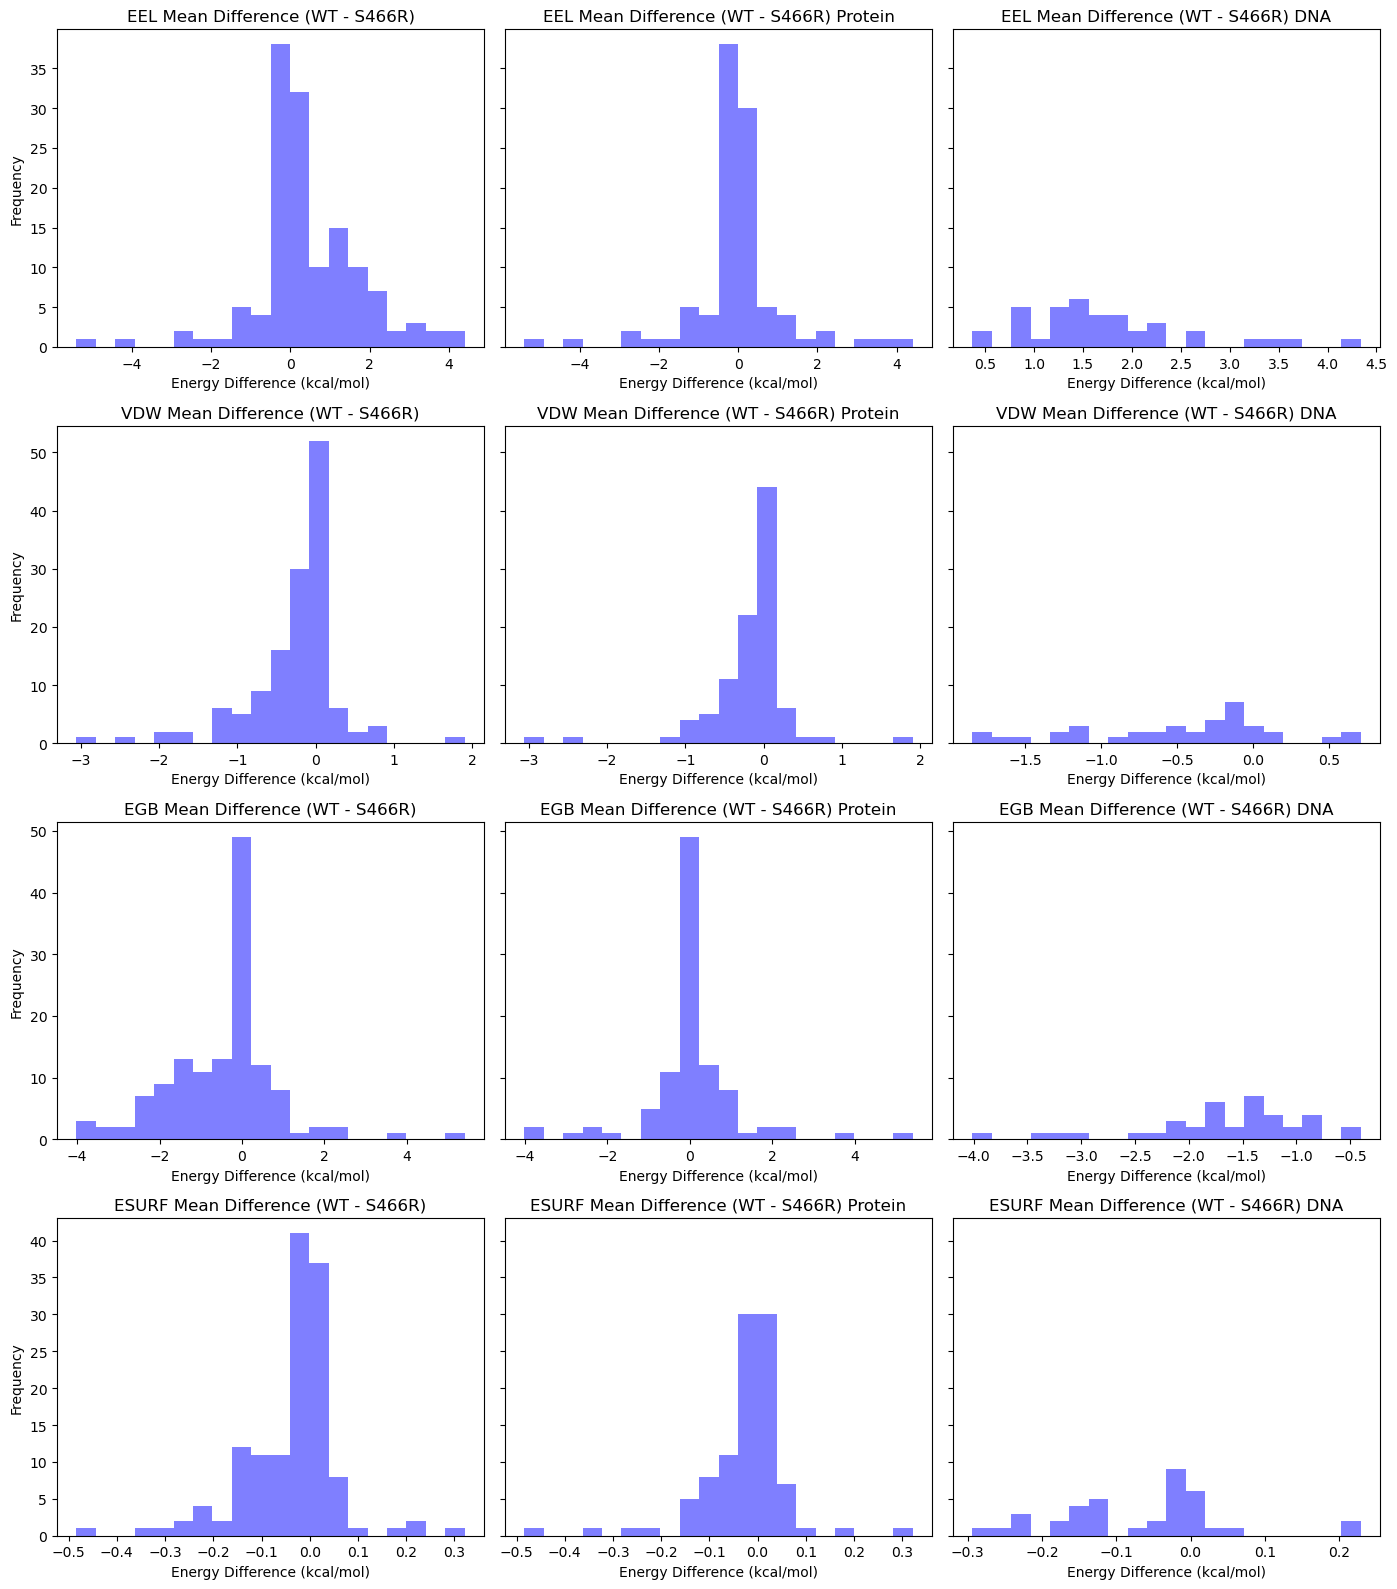

In [46]:
# columns ending in '_diff'
diff_columns = common_df.filter(like='_diff').columns
n_rows = len(diff_columns)

fig, axes = plt.subplots(n_rows, 3, figsize=(14, 4 * n_rows), sharey='row', squeeze=False)

for row, diff_col in enumerate(diff_columns):
    # Extract the energy term name
    term_name = diff_col.replace('_diff', '')
    
    # All residues
    axes[row, 0].hist(common_df[diff_col], bins=20, alpha=0.5, color='blue')
    axes[row, 0].set_title(f'{term_name} Mean Difference (WT - S466R)')
    axes[row, 0].set_xlabel('Energy Difference (kcal/mol)')
    axes[row, 0].set_ylabel('Frequency')
    
    # Protein chains (A, B)
    axes[row, 1].hist(common_df[diff_col][common_df['chain'].isin(['A', 'B'])], bins=20, alpha=0.5, color='blue')
    axes[row, 1].set_title(f'{term_name} Mean Difference (WT - S466R) Protein')
    axes[row, 1].set_xlabel('Energy Difference (kcal/mol)')
    
    # DNA chains (C, D)
    axes[row, 2].hist(common_df[diff_col][common_df['chain'].isin(['C', 'D'])], bins=20, alpha=0.5, color='blue')
    axes[row, 2].set_title(f'{term_name} Mean Difference (WT - S466R) DNA')
    axes[row, 2].set_xlabel('Energy Difference (kcal/mol)')

plt.tight_layout()
plt.show()

EEL outlyers

In [47]:
common_df[common_df['EEL_diff'] > 3][['resid_adj', 'chain', 'Electrostatic_mean_WT', 'Electrostatic_mean_S466R', 'EEL_diff']].sort_values('EEL_diff', ascending=False)

,resid_adj,chain,Electrostatic_mean_WT,Electrostatic_mean_S466R,EEL_diff
11,421,A,29.022399,24.620559,4.401840
112,22,C,0.080778,-4.256826,4.337605
2,418,A,-28.401906,-32.227009,3.825103
121,6,D,-2.463796,-6.205715,3.741919
115,7,C,-3.385413,-6.753752,3.368340
113,6,C,-0.491610,-3.774644,3.283034
63,428,B,29.555958,26.458942,3.097016


VDW outliers

In [48]:
common_df[common_df['VDW_diff'] > 1][
    ['resid_adj', 'chain', 'van der Waals_mean_WT', 'van der Waals_mean_S466R', 'VDW_diff']].sort_values('VDW_diff', ascending=False)

,resid_adj,chain,van der Waals_mean_WT,van der Waals_mean_S466R,VDW_diff
2,418,A,-1.408623,-3.311713,1.90309


In [49]:
common_df[common_df['VDW_diff'] < -1.5][
    ['resid_adj', 'chain', 'van der Waals_mean_WT', 'van der Waals_mean_S466R', 'VDW_diff']].sort_values('VDW_diff', ascending=False)

,resid_adj,chain,van der Waals_mean_WT,van der Waals_mean_S466R,VDW_diff
111,19,C,-2.358500,-0.789661,-1.568839
113,6,C,-3.088114,-1.473483,-1.614631
115,7,C,-5.559581,-3.733383,-1.826198
116,8,C,-5.768952,-3.920768,-1.848184
11,421,A,-2.688174,-0.307954,-2.380220
52,418,B,-6.049578,-2.994963,-3.054614


EGB outliers

In [50]:
common_df[common_df['EGB_diff'] < -3][
    ['resid_adj', 'chain', 'Polar Solvation_mean_WT', 'Polar Solvation_mean_S466R', 'EGB_diff']
].sort_values('EGB_diff', ascending=True)

,resid_adj,chain,Polar Solvation_mean_WT,Polar Solvation_mean_S466R,EGB_diff
11,421,A,-28.140233,-24.122984,-4.017249
112,22,C,-0.075699,3.936158,-4.011856
2,418,A,27.720366,31.526600,-3.806234
121,6,D,2.313001,5.777598,-3.464597
115,7,C,3.297399,6.421430,-3.124032


In [51]:
common_df[(common_df['EGB_diff'] < -3)][
    ['resid_adj', 'chain', 'Polar Solvation_mean_WT', 'Polar Solvation_mean_S466R', 'EGB_diff']
].sort_values('EGB_diff', ascending=True)

,resid_adj,chain,Polar Solvation_mean_WT,Polar Solvation_mean_S466R,EGB_diff
11,421,A,-28.140233,-24.122984,-4.017249
112,22,C,-0.075699,3.936158,-4.011856
2,418,A,27.720366,31.526600,-3.806234
121,6,D,2.313001,5.777598,-3.464597
115,7,C,3.297399,6.421430,-3.124032


Energy metrics breakdown per DNA chain

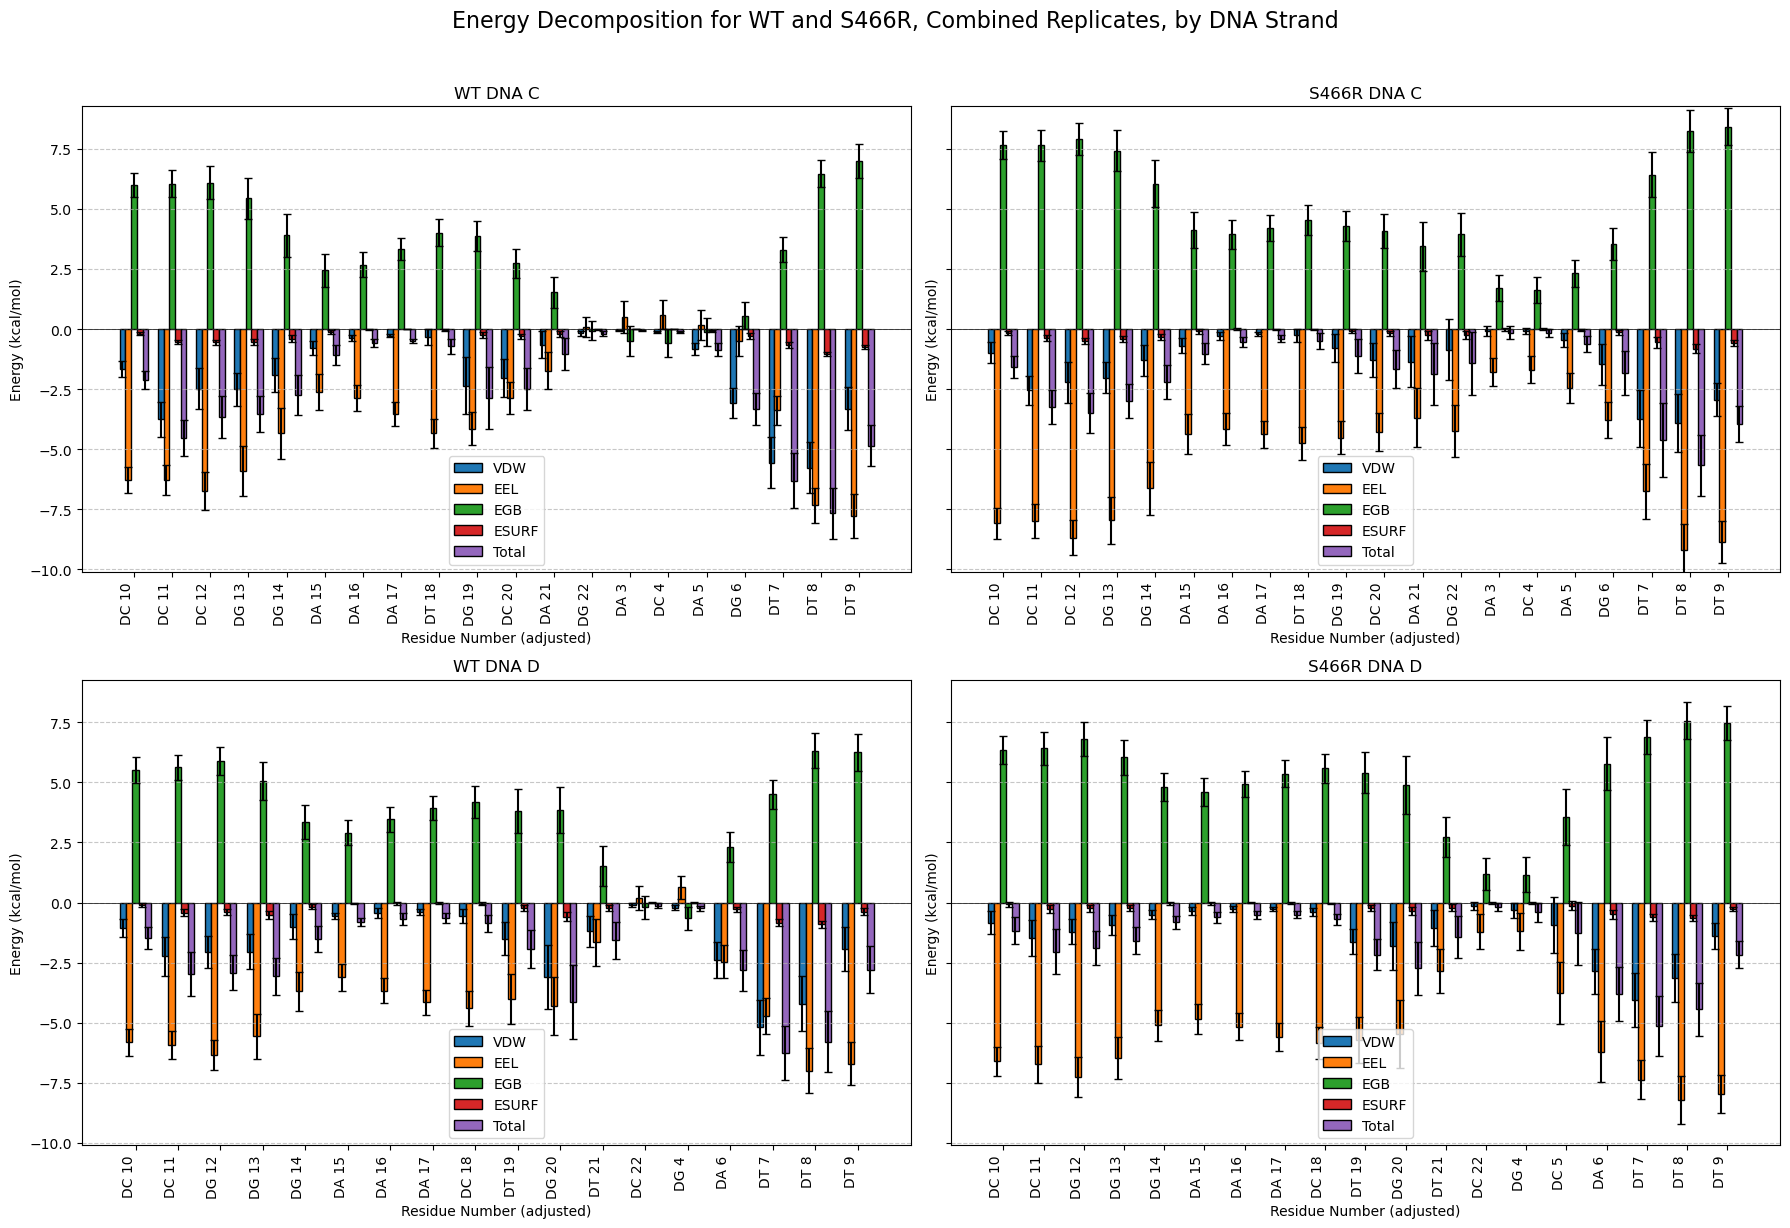

In [52]:
df_wt_dnaC = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "C"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_dnaC= S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "C"].sort_values(by=["resid_adj"], ascending=True)

df_wt_dnaD = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "D"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_dnaD = S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "D"].sort_values(by=["resid_adj"], ascending=True)

energy_terms = [
    'van der Waals_mean', 'Electrostatic_mean', 'Polar Solvation_mean',
    'Non-Polar Solv._mean', 'TOTAL_mean'
]
std_terms = [
    'van der Waals_std', 'Electrostatic_std', 'Polar Solvation_std',
    'Non-Polar Solv._std', 'TOTAL_std'
]

# Find global min and max across all energy terms
all_data = []
for df in [df_wt_dnaC, df_S466R_dnaC, df_wt_dnaD, df_S466R_dnaD]:
    for term in energy_terms:
        all_data.append(df[term].values)
global_min = min([np.nanmin(data) for data in all_data]) * 1.1  
global_max = max([np.nanmax(data) for data in all_data]) * 1.1  

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (df_wt_dnaC, ax1, 'WT DNA C'),
    (df_S466R_dnaC, ax2, 'S466R DNA C'),
    (df_wt_dnaD, ax3, 'WT DNA D'),
    (df_S466R_dnaD, ax4, 'S466R DNA D'),
]

# Plotting parameters
n_terms = len(energy_terms)  
bar_width = 0.15 
labels = ['VDW', 'EEL', 'EGB', 'ESURF', 'Total'] 

for df, ax, title in plots:
    filtered_df = df.copy()
    filtered_df['resid_adj'] = pd.to_numeric(filtered_df['resid_adj'])
    
    # Get residue positions and labels
    residues = filtered_df['resid_adj'].values
    res_labels = [f"{resnm} {resid}" for resnm, resid in zip(filtered_df['resnm'], filtered_df['resid_adj'])]
    n_residues = len(residues)
    
    # Set x positions for bars
    x = np.arange(n_residues)  # Base positions for residues
    for i, (term, std, label) in enumerate(zip(energy_terms, std_terms, labels)):
        x_pos = x + i * bar_width - (n_terms - 1) * bar_width / 2
        ax.bar(
            x_pos,
            filtered_df[term],
            yerr=filtered_df[std],
            width=bar_width,
            edgecolor='black',
            capsize=3,
            label=label
        )
    
    # Customize axes
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.set_xticks(x)
    ax.set_xticklabels(res_labels, rotation=90, ha='right')
    ax.legend(loc='best')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_ylim(global_min, global_max)

plt.suptitle('Energy Decomposition for WT and S466R, Combined Replicates, by DNA Strand', fontsize=16, y=1.02)

plt.tight_layout()
plt.show()

#### Interpretation - Energy metrics outliers